<a href="https://colab.research.google.com/github/AnastasiaaAlekseichuk/DCCAS_Alekseichuk/blob/main/%D0%9B%D0%A02_Alekseichuk/LR2_variant1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа № 2. Консолидация разнородных источников: CSV + Excel + JSON → SQLite → аналитика

**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Среда:** один ноутбук Google Colab, без Docker и без внешней СУБД · до 10 баллов за основную часть

## Цель

Собрать данные из трёх источников разного формата, провести аудит и очистку, загрузить результат в локальную реляционную базу SQLite, рассчитать выручку по субъектам и довести результат до управленческих выводов.

## Задачи

1. Прочитать три источника: справочник субъектов (CSV), события с объёмом (Excel) и цены по событиям (JSON).
2. Провести **аудит качества** по шести измерениям: полнота, уникальность, согласованность, валидность, целостность, точность.
3. Очистить данные с ведением **журнала изменений** и карантина: ни одна строка не исчезает молча.
4. Спроектировать схему в SQLite: первичные и внешние ключи, ограничения `CHECK`, индексы.
5. Показать и устранить эффект **fan-out при соединении один-ко-многим** — главную причину завышенной выручки в отчётности.
6. Сверить расчёт на SQL и в pandas, провести аналитику (концентрация, Парето и ABC, сезонность, структура по классам) и сформулировать выводы.
7. **Дополнительно, по желанию:** выгрузить витрину в BigQuery и повторить расчёт (необязательный раздел; основная работа полностью выполняется в SQLite).

## Чем эта работа отличается от версии с Docker и PostgreSQL

| | Прежняя схема | Текущая схема |
|---|---|---|
| Инфраструктура | Docker Compose, контейнер PostgreSQL, Jupyter в контейнере | один ноутбук в Colab |
| СУБД | PostgreSQL 15 на порту 5432 | SQLite: база — один файл рядом с ноутбуком |
| Запуск | установка Docker, `docker compose up`, проброс портов | «Выполнить все» |
| Что теряем | ничего существенного для учебной задачи | — |
| Что приобретаем | — | воспроизводимость, отсутствие проблем с портами и правами |

SQL остаётся тем же: `CREATE TABLE`, ключи, `JOIN`, `GROUP BY`, оконные конструкции и CTE. Отличия SQLite от PostgreSQL, важные для работы, разобраны в теоретическом блоке.

## Что сдаётся

Ноутбук **с выводами ячеек**, файл базы `*.sqlite` и выгрузка витрины, опубликованные в личном репозитории GitHub; в LMS сдаётся ссылка на репозиторий.

## Как выполнять работу

1. **Файл → Сохранить копию на Диске.**
2. В шаге 1 укажите номер варианта, выданный преподавателем. От него зависят предметная область, объём данных и набор дефектов.
3. Выполняйте ячейки сверху вниз: генерация источников → аудит → очистка → SQLite → аналитика → выводы.
4. Перед каждым шагом дано методическое обоснование, после — интерпретация результата. Места с пометкой `TODO` дописываете вы.
5. Раздел BigQuery необязателен. Он включается флагом `ENABLE_BIGQUERY` и требует аккаунта Google Cloud; без него работа выполняется полностью.
6. Перед сдачей запустите самопроверку: должно быть «Выполнено: 11 из 11».

**Важно про данные.** Источники генерируются кодом и намеренно содержат дефекты: дубликаты, пропуски, два формата даты, числа строками с валютой, отрицательные цены, записи с несуществующим внешним ключом. Это не ошибка генератора — это предмет работы. Задача аналитика не в том, чтобы получить красивое число, а в том, чтобы знать, из чего оно посчитано и что было отброшено.

## Теоретический блок

### 1. Консолидация: что это и где ломается

Консолидация — приведение данных из разных источников к единой модели, пригодной для анализа. Типовой конвейер:

```
Извлечение (Extract) → Профилирование → Очистка → Сопоставление ключей → Загрузка (Load) → Витрина → Анализ
```

Три формата, с которыми вы работаете, ведут себя по-разному:

| Формат | Что гарантирует | Типичные проблемы |
|---|---|---|
| **CSV** | ничего, кроме текста | кодировка, разделитель, отсутствие типов: `007` превращается в `7`, а `2025-03-17` — в дату не всегда |
| **Excel** | типы ячеек и автоформатирование | «умное» приведение типов, скрытые пробелы, даты как числа, разные листы и объединённые ячейки |
| **JSON** | структуру и типы | вложенность, разный набор полей у записей, числа строками |

Общее правило: **читать всё как текст и приводить типы явно**. В работе так и сделано — `dtype=str` при чтении, затем контролируемое преобразование.

### 2. Шесть измерений качества данных

| Измерение | Вопрос | Как проверяется в работе |
|---|---|---|
| Полнота | всё ли на месте | доля непустых значений по каждой колонке |
| Уникальность | нет ли дублей | дубликаты строк и повторы ключей |
| Согласованность | одинаково ли записано | два формата даты, числа с валютой и пробелами |
| Валидность | попадает ли в допустимый диапазон | отрицательные цены, нулевой объём |
| Целостность | сходятся ли ссылки между таблицами | события с `entity_id`, которого нет в справочнике |
| Точность | похоже ли на правду | выбросы по правилу 3×IQR |

Принципиальное правило работы: **пропуск не равен нулю**. Замена `NaN` на 0 занижает средние и портит медианы; строка с непригодным значением отправляется в карантин, а не удаляется молча.

### 3. Ключи, кардинальность и fan-out — центральная идея работы

У связи между таблицами есть кардинальность:

* **1 : 1** — одной записи соответствует одна;
* **1 : N** — у события несколько ценовых строк (разные классы);
* **N : M** — требует таблицы-связки.

Если соединить три таблицы «в лоб», строка события повторится столько раз, сколько у него ценовых строк. Это и есть **fan-out**: сумма объёма и выручки завышается кратно.

```
events (1 строка, 180 единиц)      prices (3 строки: 5 000, 12 000, 25 000)
        └──────────── JOIN ────────────┘
результат: 3 строки по 180 единиц → SUM(volume) = 540 вместо 180
```

Правильный порядок действий: **сначала свернуть подчинённую таблицу до уровня родителя (агрегировать цены по событию), потом соединять**. В работе оба варианта считаются и сравниваются численно — вы увидите коэффициент завышения на своих данных.

Формула расчёта после свёртки:

$$
Revenue_{entity} = \sum_{e \in events(entity)} volume_e \cdot \overline{price}_e,
\qquad
\overline{price}_e = \frac{1}{n_e}\sum_{i=1}^{n_e} price_{e,i}
$$

Среднее здесь — упрощение. Если известно количество проданных единиц по каждому классу, корректнее взвешенное среднее; это вынесено в задание со звёздочкой.

### 4. SQLite: что важно знать

SQLite — встраиваемая СУБД: вся база это один файл, сервер не нужен. Именно поэтому она заменяет здесь PostgreSQL в контейнере.

| Особенность | Следствие для работы |
|---|---|
| Внешние ключи **выключены** по умолчанию | обязательно `PRAGMA foreign_keys = ON;` в начале сессии |
| Динамическая типизация (type affinity) | в колонку `INTEGER` можно записать текст: типы контролирует ваш код и `CHECK` |
| Нет отдельного типа `DATE` | даты хранятся строками `YYYY-MM-DD` — формат, который корректно сортируется |
| Нет `TRUE/FALSE` | используйте 0 и 1 |
| Одна запись за раз, читателей много | для учебной задачи и витрин на миллионы строк этого достаточно |
| Поддерживает CTE и оконные функции | `WITH ... AS`, `ROW_NUMBER() OVER (...)` работают как в PostgreSQL |

Чего в SQLite нет по сравнению с PostgreSQL: серверного доступа по сети, ролей и прав, материализованных представлений, параллельной записи, богатых типов (`JSONB`, `ARRAY`, геоданные). Когда эти возможности понадобятся, переносится тот же SQL — меняется строка подключения.

### 5. Три уровня хранения: когда что выбирать

| | SQLite | PostgreSQL | BigQuery |
|---|---|---|---|
| Развёртывание | файл, ноль настройки | сервер или контейнер | облачный сервис |
| Объём | до сотен миллионов строк на одной машине | терабайты | петабайты |
| Модель оплаты | бесплатно | инфраструктура | за объём прочитанных данных |
| Параллельная запись | одна | много | пакетная загрузка |
| Где уместна | прототип, учебная работа, витрина одного аналитика | продуктовая база, многопользовательский доступ | аналитика на больших объёмах, редкие тяжёлые запросы |

Учебная витрина этой работы — десятки тысяч строк. Для неё SQLite избыточно достаточен, и это тоже профессиональный вывод: инструмент выбирается под объём и режим доступа, а не по громкости названия.

### Шаг 1. Окружение и параметры варианта

**Методическое обоснование.** Colab — одноразовая среда: нужные библиотеки проверяются и при необходимости доустанавливаются, рабочая папка создаётся заново. Номер варианта задаёт предметную область, объём генерации и уровень дефектов — от него детерминированно зависят все дальнейшие числа, поэтому результат воспроизводим.

In [1]:
#@title Шаг 1. Окружение и параметры варианта { display-mode: "form" }
VARIANT = 1                  #@param {type:"slider", min:1, max:30, step:1}
ENABLE_BIGQUERY = False      #@param {type:"boolean"}
RANDOM_CHECK = True          #@param {type:"boolean"}

import importlib, json, math, os, re, sqlite3, subprocess, sys, textwrap, warnings
from datetime import datetime, timedelta
from pathlib import Path

def ensure(pkg, module=None):
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("pandas", "pandas"), ("numpy", "numpy"), ("openpyxl", "openpyxl"),
                 ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.width", 170, "display.max_columns", 50, "display.float_format", "{:,.2f}".format)

WORK = Path("/content/pw2" if Path("/content").exists() else "pw2_work")
DATA = WORK / "data"
DATA.mkdir(parents=True, exist_ok=True)
DB_PATH = WORK / f"consolidation_variant_{VARIANT}.sqlite"

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def nf(x, digits=0):
    """Число с пробелом-разделителем разрядов: 1 234 567."""
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "—"
    return f"{x:,.{digits}f}".replace(",", " ")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"sqlite3 {sqlite3.sqlite_version}")
print(f"Рабочая папка: {WORK}")

Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | sqlite3 3.45.1
Рабочая папка: /content/pw2


In [2]:
#@title Шаг 1.1. Конфигурация варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"domain": "Авиаперевозки",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют",
"seed": 1007,
"n_parents": 9,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
},
{
"id": 2,
"domain": "Розничная сеть",
"parent": "Магазины",
"event": "Чеки",
"price": "Позиции чека",
"unit": "единиц товара",
"cls": "категория товара",
"analytics": "ABC-анализ магазинов: какие точки дают 80 % выручки",
"seed": 1014,
"n_parents": 10,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Магазины — CSV, Чеки — XLSX, Позиции чека — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Магазины»"
},
{
"id": 3,
"domain": "Логистика",
"parent": "Перевозчики",
"event": "Отгрузки",
"price": "Тарифы",
"unit": "паллет",
"cls": "тип тарифа",
"analytics": "Загрузка перевозчиков: связь объёма и средней ставки",
"seed": 1021,
"n_parents": 11,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Перевозчики — CSV, Отгрузки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 4,
"domain": "Телеком",
"parent": "Операторы",
"event": "Сессии связи",
"price": "Тарификация",
"unit": "минут",
"cls": "тарифный план",
"analytics": "Доля тарифных планов в выручке и средний чек сессии",
"seed": 1028,
"n_parents": 12,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы — CSV, Сессии связи — XLSX, Тарификация — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 5,
"domain": "Банковский ритейл",
"parent": "Отделения",
"event": "Операции",
"price": "Комиссии",
"unit": "транзакций",
"cls": "тип комиссии",
"analytics": "Эффективность отделений: выручка на одну операцию",
"seed": 1035,
"n_parents": 8,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Отделения — CSV, Операции — XLSX, Комиссии — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отделения»"
},
{
"id": 6,
"domain": "Гостиничный бизнес",
"parent": "Отели",
"event": "Бронирования",
"price": "Тарифы номеров",
"unit": "ночей",
"cls": "категория номера",
"analytics": "Сезонность загрузки и вклад категорий номеров",
"seed": 1042,
"n_parents": 9,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Отели — CSV, Бронирования — XLSX, Тарифы номеров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отели»"
},
{
"id": 7,
"domain": "Образовательные услуги",
"parent": "Центры",
"event": "Группы",
"price": "Стоимость обучения",
"unit": "слушателей",
"cls": "формат обучения",
"analytics": "Выручка на слушателя и сравнение форматов",
"seed": 1049,
"n_parents": 10,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Центры — CSV, Группы — XLSX, Стоимость обучения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Центры»"
},
{
"id": 8,
"domain": "Медицинские клиники",
"parent": "Клиники",
"event": "Приёмы",
"price": "Прейскурант",
"unit": "пациентов",
"cls": "вид услуги",
"analytics": "Структура выручки по видам услуг и загрузка клиник",
"seed": 1056,
"n_parents": 11,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Клиники — CSV, Приёмы — XLSX, Прейскурант — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клиники»"
},
{
"id": 9,
"domain": "Энергосбыт",
"parent": "Сбытовые компании",
"event": "Поставки",
"price": "Тарифы",
"unit": "МВт·ч",
"cls": "категория потребителя",
"analytics": "Концентрация выручки по категориям потребителей",
"seed": 1063,
"n_parents": 12,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Сбытовые компании — CSV, Поставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сбытовые компании»"
},
{
"id": 10,
"domain": "Маркетплейс",
"parent": "Продавцы",
"event": "Заказы",
"price": "Цены товаров",
"unit": "единиц",
"cls": "категория товара",
"analytics": "Топ продавцов и доля категорий в обороте",
"seed": 1070,
"n_parents": 8,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Продавцы — CSV, Заказы — XLSX, Цены товаров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Продавцы»"
},
{
"id": 11,
"domain": "Общественный транспорт",
"parent": "Перевозчики",
"event": "Маршруты-рейсы",
"price": "Тарифы проезда",
"unit": "пассажиров",
"cls": "тип билета",
"analytics": "Выручка по типам билетов и пиковые месяцы",
"seed": 1077,
"n_parents": 9,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Перевозчики — CSV, Маршруты-рейсы — XLSX, Тарифы проезда — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 12,
"domain": "Страхование",
"parent": "Агентства",
"event": "Договоры",
"price": "Тарифные ставки",
"unit": "объектов",
"cls": "вид страхования",
"analytics": "Средняя премия по видам страхования и вклад агентств",
"seed": 1084,
"n_parents": 10,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Агентства — CSV, Договоры — XLSX, Тарифные ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Агентства»"
},
{
"id": 13,
"domain": "Грузовые ж/д перевозки",
"parent": "Операторы вагонов",
"event": "Отправки",
"price": "Ставки",
"unit": "тонн",
"cls": "род груза",
"analytics": "Доходность по родам груза и сезонность отправок",
"seed": 1091,
"n_parents": 11,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы вагонов — CSV, Отправки — XLSX, Ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы вагонов»"
},
{
"id": 14,
"domain": "Общепит",
"parent": "Рестораны",
"event": "Заказы",
"price": "Цены блюд",
"unit": "порций",
"cls": "категория меню",
"analytics": "Средний чек и вклад категорий меню",
"seed": 1098,
"n_parents": 12,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Рестораны — CSV, Заказы — XLSX, Цены блюд — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Рестораны»"
},
{
"id": 15,
"domain": "Фитнес-сети",
"parent": "Клубы",
"event": "Визиты и покупки",
"price": "Прайс услуг",
"unit": "услуг",
"cls": "тип абонемента",
"analytics": "Выручка на клуб и структура абонементов",
"seed": 1105,
"n_parents": 8,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Клубы — CSV, Визиты и покупки — XLSX, Прайс услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клубы»"
},
{
"id": 16,
"domain": "Аренда спецтехники",
"parent": "Парки техники",
"event": "Смены аренды",
"price": "Ставки аренды",
"unit": "машино-часов",
"cls": "тип техники",
"analytics": "Утилизация парка и доходность типов техники",
"seed": 1112,
"n_parents": 9,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Парки техники — CSV, Смены аренды — XLSX, Ставки аренды — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Парки техники»"
},
{
"id": 17,
"domain": "Курьерская доставка",
"parent": "Службы доставки",
"event": "Доставки",
"price": "Тарифы",
"unit": "посылок",
"cls": "скорость доставки",
"analytics": "Доля экспресс-доставки в выручке",
"seed": 1119,
"n_parents": 10,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Службы доставки — CSV, Доставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Службы доставки»"
},
{
"id": 18,
"domain": "Оптовая торговля",
"parent": "Дистрибьюторы",
"event": "Поставки",
"price": "Прайс-листы",
"unit": "коробов",
"cls": "товарная группа",
"analytics": "Парето по товарным группам и вклад дистрибьюторов",
"seed": 1126,
"n_parents": 11,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Дистрибьюторы — CSV, Поставки — XLSX, Прайс-листы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Дистрибьюторы»"
},
{
"id": 19,
"domain": "Автосервис",
"parent": "Сервисные центры",
"event": "Заказ-наряды",
"price": "Прейскурант работ",
"unit": "нормо-часов",
"cls": "вид работ",
"analytics": "Выручка по видам работ и загрузка центров",
"seed": 1133,
"n_parents": 12,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Сервисные центры — CSV, Заказ-наряды — XLSX, Прейскурант работ — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисные центры»"
},
{
"id": 20,
"domain": "Цифровые подписки",
"parent": "Сервисы",
"event": "Подписки",
"price": "Тарифные планы",
"unit": "подписчиков",
"cls": "план подписки",
"analytics": "Структура подписной базы и выручка на подписчика",
"seed": 1140,
"n_parents": 8,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Сервисы — CSV, Подписки — XLSX, Тарифные планы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисы»"
},
{
"id": 21,
"domain": "Сельхозпроизводство",
"parent": "Хозяйства",
"event": "Партии отгрузки",
"price": "Закупочные цены",
"unit": "тонн",
"cls": "культура",
"analytics": "Доходность культур и сезонность отгрузок",
"seed": 1147,
"n_parents": 9,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Хозяйства — CSV, Партии отгрузки — XLSX, Закупочные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Хозяйства»"
},
{
"id": 22,
"domain": "Строительный ритейл",
"parent": "Гипермаркеты",
"event": "Продажи",
"price": "Цены материалов",
"unit": "единиц",
"cls": "группа материалов",
"analytics": "Сезонность продаж и вклад групп материалов",
"seed": 1154,
"n_parents": 10,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Гипермаркеты — CSV, Продажи — XLSX, Цены материалов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Гипермаркеты»"
},
{
"id": 23,
"domain": "Морские перевозки",
"parent": "Судоходные линии",
"event": "Рейсы судов",
"price": "Фрахтовые ставки",
"unit": "TEU",
"cls": "тип контейнера",
"analytics": "Доходность линий и структура по типам контейнеров",
"seed": 1161,
"n_parents": 11,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Судоходные линии — CSV, Рейсы судов — XLSX, Фрахтовые ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Судоходные линии»"
},
{
"id": 24,
"domain": "Аптечные сети",
"parent": "Аптеки",
"event": "Продажи",
"price": "Цены препаратов",
"unit": "упаковок",
"cls": "группа препаратов",
"analytics": "Вклад товарных групп и сравнение точек",
"seed": 1168,
"n_parents": 12,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Аптеки — CSV, Продажи — XLSX, Цены препаратов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Аптеки»"
},
{
"id": 25,
"domain": "Кинотеатры",
"parent": "Кинотеатры",
"event": "Сеансы",
"price": "Цены билетов",
"unit": "зрителей",
"cls": "тип сеанса",
"analytics": "Заполняемость залов и выручка по типам сеансов",
"seed": 1175,
"n_parents": 8,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Кинотеатры — CSV, Сеансы — XLSX, Цены билетов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Кинотеатры»"
},
{
"id": 26,
"domain": "Промышленное производство",
"parent": "Заводы",
"event": "Партии продукции",
"price": "Отпускные цены",
"unit": "тонн",
"cls": "марка продукции",
"analytics": "Вклад марок продукции и сезонность отгрузок",
"seed": 1182,
"n_parents": 9,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Заводы — CSV, Партии продукции — XLSX, Отпускные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Заводы»"
},
{
"id": 27,
"domain": "Рекламные площадки",
"parent": "Площадки",
"event": "Кампании",
"price": "Ставки размещения",
"unit": "показов (тыс.)",
"cls": "формат размещения",
"analytics": "Доходность форматов и концентрация выручки",
"seed": 1189,
"n_parents": 10,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Площадки — CSV, Кампании — XLSX, Ставки размещения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Площадки»"
},
{
"id": 28,
"domain": "ЖКХ",
"parent": "Управляющие компании",
"event": "Начисления",
"price": "Тарифы услуг",
"unit": "объектов",
"cls": "вид услуги",
"analytics": "Структура начислений и сравнение управляющих компаний",
"seed": 1196,
"n_parents": 11,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Управляющие компании — CSV, Начисления — XLSX, Тарифы услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Управляющие компании»"
},
{
"id": 29,
"domain": "Каршеринг",
"parent": "Операторы",
"event": "Поездки",
"price": "Тарифы поездок",
"unit": "минут",
"cls": "класс автомобиля",
"analytics": "Выручка на поездку и вклад классов автомобилей",
"seed": 1203,
"n_parents": 12,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Операторы — CSV, Поездки — XLSX, Тарифы поездок — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 30,
"domain": "Авиаперевозки (эталон преподавателя)",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки",
"seed": 1210,
"n_parents": 8,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
}
]

# Предметные атрибуты событий (XLSX) и названия классов цен (JSON) для каждого варианта.
# detail — описательный столбец события: «pair» — пара «откуда — куда», «one» — одно значение;
# kind — второй описательный столбец (4 значения); classes — классы цен от дешёвого к дорогому.
# Эти столбцы описывают событие, но в расчёт выручки не входят: выручка = объём × цена.
EVENT_ATTRS = {
    1: {"detail": ["route", "pair", None], "kind": ["aircraft_type", ["Узкофюзеляжный", "Широкофюзеляжный", "Региональный", "Турбовинтовой"]], "classes": ["Эконом", "Комфорт", "Бизнес"]},
    2: {"detail": ["payment_method", "one", ["Наличные", "Банковская карта", "СБП", "Карта + бонусы"]], "kind": ["checkout_type", ["Касса", "Касса самообслуживания", "Онлайн-заказ", "Экспресс-касса"]], "classes": ["Бакалея", "Бытовая химия", "Электроника"]},
    3: {"detail": ["route", "pair", None], "kind": ["vehicle_type", ["Фура 20 т", "Рефрижератор", "Малотоннажный", "Контейнеровоз"]], "classes": ["Базовый", "Срочный", "Экспресс"]},
    4: {"detail": ["network", "one", ["2G", "3G", "4G", "5G"]], "kind": ["session_type", ["Голос", "Мобильный интернет", "Роуминг", "SMS-пакет"]], "classes": ["Базовый", "Безлимитный", "Корпоративный"]},
    5: {"detail": ["service_channel", "one", ["Касса", "Банкомат", "Интернет-банк", "Мобильное приложение"]], "kind": ["client_segment", ["Массовый", "Зарплатный", "Премиальный", "МСБ"]], "classes": ["Переводы", "Валютные операции", "Инкассация"]},
    6: {"detail": ["booking_channel", "one", ["Сайт отеля", "Онлайн-агрегатор", "Турагентство", "Корпоративный договор"]], "kind": ["guest_type", ["Деловой", "Туристический", "Семейный", "Групповой"]], "classes": ["Стандарт", "Делюкс", "Люкс"]},
    7: {"detail": ["course_area", "one", ["IT", "Иностранные языки", "Управление", "Подготовка к экзаменам"]], "kind": ["audience", ["Школьники", "Студенты", "Взрослые", "Корпоративные клиенты"]], "classes": ["Онлайн", "Смешанный", "Очный"]},
    8: {"detail": ["specialty", "one", ["Терапия", "Педиатрия", "Стоматология", "Кардиология", "Неврология", "Офтальмология"]], "kind": ["payment_type", ["ОМС", "ДМС", "Платно", "Абонемент"]], "classes": ["Консультация", "Диагностика", "Процедура"]},
    9: {"detail": ["voltage_level", "one", ["ВН", "СН-1", "СН-2", "НН"]], "kind": ["contract_type", ["Энергоснабжение", "Купля-продажа", "Регулируемый", "Свободный рынок"]], "classes": ["Население", "Бюджетные организации", "Промышленность"]},
    10: {"detail": ["fulfillment", "one", ["Склад площадки", "Склад продавца", "Экспресс-доставка", "Самовывоз"]], "kind": ["order_channel", ["Мобильное приложение", "Сайт", "Партнёрский сайт", "Реклама в соцсетях"]], "classes": ["Товары для дома", "Одежда", "Электроника"]},
    11: {"detail": ["line", "one", ["Маршрут 1", "Маршрут 5", "Маршрут 12", "Маршрут 18", "Маршрут 24", "Маршрут 31", "Маршрут 37", "Маршрут 42", "Маршрут 55", "Маршрут 63", "Маршрут 70", "Маршрут 88"]], "kind": ["vehicle_type", ["Автобус", "Трамвай", "Троллейбус", "Электробус"]], "classes": ["Разовый", "Проездной на месяц", "Проездной на год"]},
    12: {"detail": ["client_type", "one", ["Физическое лицо", "ИП", "Малый бизнес", "Крупный бизнес"]], "kind": ["sales_channel", ["Офис агентства", "Онлайн", "Банк-партнёр", "Автосалон"]], "classes": ["ОСАГО", "Имущество", "КАСКО"]},
    13: {"detail": ["route", "pair", None], "kind": ["wagon_type", ["Полувагон", "Крытый вагон", "Цистерна", "Платформа"]], "classes": ["Уголь", "Зерно", "Нефтепродукты"]},
    14: {"detail": ["service_format", "one", ["В зале", "Навынос", "Доставка", "Банкет"]], "kind": ["daypart", ["Завтрак", "Обед", "Ужин", "Поздний вечер"]], "classes": ["Напитки", "Основные блюда", "Фирменные сеты"]},
    15: {"detail": ["visit_zone", "one", ["Тренажёрный зал", "Бассейн", "Групповые программы", "Единоборства"]], "kind": ["client_type", ["Новый клиент", "Постоянный", "Корпоративный", "Гостевой визит"]], "classes": ["Разовый", "Месячный", "Годовой"]},
    16: {"detail": ["site_type", "one", ["Жилое строительство", "Дорожные работы", "Промышленный объект", "Коммунальные работы"]], "kind": ["rental_mode", ["С оператором", "Без оператора", "Долгосрочная", "Почасовая"]], "classes": ["Мини-погрузчик", "Экскаватор", "Автокран"]},
    17: {"detail": ["route", "pair", None], "kind": ["parcel_size", ["Документы", "Малая (S)", "Средняя (M)", "Крупная (L)"]], "classes": ["Стандарт", "Ускоренная", "Экспресс"]},
    18: {"detail": ["client_channel", "one", ["Розничные сети", "HoReCa", "Независимая розница", "Онлайн-ретейл"]], "kind": ["delivery_mode", ["Доставка дистрибьютора", "Самовывоз", "Транзит со склада", "Кросс-докинг"]], "classes": ["Бакалея", "Напитки", "Кондитерские изделия"]},
    19: {"detail": ["car_class", "one", ["Отечественный", "Иномарка эконом", "Иномарка бизнес", "Коммерческий транспорт"]], "kind": ["visit_reason", ["Плановое ТО", "Ремонт", "Шиномонтаж", "Диагностика"]], "classes": ["Слесарные работы", "Электрика и диагностика", "Кузовные работы"]},
    20: {"detail": ["platform", "one", ["iOS", "Android", "Веб", "Smart TV"]], "kind": ["acquisition", ["Органика", "Реклама", "Промокод", "Партнёр"]], "classes": ["Базовый", "Стандарт", "Премиум"]},
    21: {"detail": ["buyer_type", "one", ["Элеватор", "Перерабатывающий завод", "Экспорт", "Трейдер"]], "kind": ["transport", ["Автотранспорт", "Железная дорога", "Речной транспорт", "Самовывоз"]], "classes": ["Пшеница", "Подсолнечник", "Соя"]},
    22: {"detail": ["sales_channel", "one", ["Торговый зал", "Интернет-магазин", "Отдел для профи", "Самовывоз со склада"]], "kind": ["client_type", ["Частный клиент", "Бригада", "Строительная компания", "Дизайнер"]], "classes": ["Крепёж и расходники", "Отделочные материалы", "Инструмент"]},
    23: {"detail": ["route", "pair", ["Новороссийск", "Санкт-Петербург", "Владивосток", "Восточный", "Усть-Луга", "Мурманск", "Калининград", "Шанхай", "Нинбо", "Пусан", "Мумбаи", "Стамбул"]], "kind": ["cargo_mode", ["Импорт", "Экспорт", "Транзит", "Каботаж"]], "classes": ["20' стандартный", "40' стандартный", "40' рефрижератор"]},
    24: {"detail": ["sales_channel", "one", ["Торговый зал", "Онлайн-бронирование", "Доставка", "Корпоративный заказ"]], "kind": ["shift", ["Утренняя смена", "Дневная смена", "Вечерняя смена", "Ночная смена"]], "classes": ["Безрецептурные (OTC)", "Рецептурные (Rx)", "Специализированная терапия"]},
    25: {"detail": ["hall", "one", ["Зал 1", "Зал 2", "Зал 3", "Зал 4", "Зал 5", "VIP-зал"]], "kind": ["genre", ["Анимация", "Драма", "Комедия", "Фантастика"]], "classes": ["2D", "3D", "IMAX"]},
    26: {"detail": ["customer_type", "one", ["Дилер", "Прямой клиент", "Экспорт", "Госзаказ"]], "kind": ["shipping", ["Железная дорога", "Автотранспорт", "Самовывоз", "Контейнер"]], "classes": ["Марка М1", "Марка М2", "Марка М3 (премиум)"]},
    27: {"detail": ["audience_age", "one", ["18–24", "25–34", "35–44", "45+"]], "kind": ["device", ["Смартфон", "Компьютер", "Smart TV", "Планшет"]], "classes": ["Баннер", "Нативный", "Видео"]},
    28: {"detail": ["building_type", "one", ["Панельный дом", "Кирпичный дом", "Монолит", "Новостройка"]], "kind": ["payment_channel", ["Банк", "Госуслуги", "Приложение УК", "Касса УК"]], "classes": ["Содержание жилья", "Водоснабжение", "Отопление"]},
    29: {"detail": ["trip_zone", "one", ["Центр", "Спальный район", "Аэропорт", "Межгород"]], "kind": ["client_type", ["Новый", "Постоянный", "Корпоративный", "Студенческий"]], "classes": ["Эконом", "Комфорт", "Премиум"]},
    30: {"detail": ["route", "pair", None], "kind": ["aircraft_type", ["Узкофюзеляжный", "Широкофюзеляжный", "Региональный", "Турбовинтовой"]], "classes": ["Эконом", "Комфорт", "Бизнес"]},
}

def variant_config(v=None):
    v = VARIANT if v is None else int(v)
    found = [x for x in VARIANTS if x["id"] == v]
    if not found:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    cfg = dict(found[0])
    cfg["event_attrs"] = EVENT_ATTRS[v]
    return cfg

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['domain']}")
print(textwrap.fill(CFG["task"], 104))
print(f"\nCSV  : {CFG['parent']}        (справочник субъектов)")
print(f"XLSX : {CFG['event']}          (события, объём в единицах: {CFG['unit']})")
print(f"       описательные столбцы: {CFG['event_attrs']['detail'][0]}, {CFG['event_attrs']['kind'][0]}")
print(f"JSON : {CFG['price']}          (цены, разрез: {CFG['cls']})")
print(f"       классы цен: {', '.join(CFG['event_attrs']['classes'])}")
print(f"\nОбъём генерации: субъектов {CFG['n_parents']}, событий {nf(CFG['n_events'])}, "
      f"уровень дефектов {'★' * CFG['defect_level']}")
print(textwrap.fill("Аналитическая задача: " + CFG["analytics"], 104))

Вариант 1 — Авиаперевозки
Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит
качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»

CSV  : Авиакомпании        (справочник субъектов)
XLSX : Рейсы          (события, объём в единицах: пассажиров)
       описательные столбцы: route, aircraft_type
JSON : Билеты          (цены, разрез: класс билета)
       классы цен: Эконом, Комфорт, Бизнес

Объём генерации: субъектов 9, событий 3 500, уровень дефектов ★★
Аналитическая задача: Сезонность перевозок: в каком месяце выручка максимальна и какие компании её
формируют


**Интерпретация.** Убедитесь, что версия pandas и SQLite вывелись, а рабочая папка создана. Номер варианта определяет всё дальнейшее: если вы его измените, перезапустите ноутбук целиком, иначе данные и выводы будут из разных вариантов.

### Шаг 2. Генерация трёх источников

**Методическое обоснование.** В реальном проекте источники приходят от разных владельцев: бухгалтерия присылает Excel, ИТ-система выгружает JSON, справочник ведётся в CSV. Мы воспроизводим эту ситуацию, включая типичные дефекты: расхождение форматов дат, числа с валютой в текстовом поле, дубликаты, битые внешние ключи. Дефекты внесены осознанно и детерминированно — при проверке преподаватель знает, что именно вы должны были найти.

**Описательные столбцы событий.** Кроме ключей, даты и объёма, в `events.xlsx` есть два столбца, которые описывают событие на языке вашей предметной области: для перевозок — маршрут, для аптек — канал продаж и смена, для кинотеатров — зал и жанр и т. д. Классы цен в `prices.json` тоже названы по предметной области. Описательные столбцы участвуют в аудите (профиль, полнота, допустимые значения) и могут использоваться в дополнительной аналитике, но в расчёт выручки не входят: выручка = объём × цена. Список столбцов вашего варианта печатает шаг 1.1.

In [3]:
#@title Шаг 2. Генерация трёх источников: CSV, XLSX, JSON { display-mode: "form" }
# Данные генерируются детерминированно от номера варианта: у каждого студента свои числа,
# но одинаковая структура. В данные намеренно внесены дефекты — их предстоит найти на шаге 3.
def generate_sources(cfg, out_dir=DATA):
    rng = np.random.default_rng(cfg["seed"])
    lvl = cfg["defect_level"]

    # ---------- 1. Справочник субъектов (CSV) --------------------------------------
    regions = ["Москва", "Санкт-Петербург", "Новосибирск", "Екатеринбург", "Казань",
               "Краснодар", "Самара", "Пермь", "Ростов-на-Дону", "Уфа", "Тюмень", "Омск"]
    n = cfg["n_parents"]
    cities = list(rng.choice(regions, n, replace=False))
    parents = pd.DataFrame({
        "entity_id": [f"E{i:03d}" for i in range(1, n + 1)],
        "entity_name": [f"{cfg['parent']} «{city}»" for city in cities],
        "region": cities,                      # регион совпадает с городом в названии
        "founded_year": rng.integers(1990, 2021, n),
    })
    # дефекты справочника: дубль строки, «грязное» имя, пропуск в регионе
    parents.loc[len(parents)] = parents.iloc[1].tolist()                       # полный дубликат
    parents.loc[2, "entity_name"] = "  " + parents.loc[2, "entity_name"].upper() + " "
    if lvl >= 2:
        parents.loc[3, "region"] = None
    parents.to_csv(out_dir / "entities.csv", index=False, encoding="utf-8")

    # ---------- 2. События с объёмом (XLSX) ----------------------------------------
    m = cfg["n_events"]
    start = datetime(2025, 1, 1)
    event_ids = [f"EV{i:06d}" for i in range(1, m + 1)]
    entity_ids = rng.choice(parents["entity_id"].iloc[:n].to_numpy(), m,
                            p=np.linspace(2.2, 0.6, n) / np.linspace(2.2, 0.6, n).sum())
    day_offsets = rng.integers(0, 365, m)
    # сезонность: летние и декабрьские месяцы нагружены сильнее
    season_boost = rng.random(m)
    dates = [start + timedelta(days=int(d)) for d in day_offsets]
    base_volume = rng.integers(60, 320, m)
    volume = np.where([d.month in (6, 7, 8, 12) for d in dates],
                      (base_volume * (1.15 + 0.25 * season_boost)).astype(int), base_volume)
    # описательные столбцы события зависят от предметной области (см. EVENT_ATTRS в шаге 1.1);
    # порядок обращений к генератору случайных чисел общий для всех вариантов
    ea = cfg["event_attrs"]
    first, second = rng.choice(regions, m), rng.choice(regions, m)
    d_col, d_kind, d_vals = ea["detail"]
    if d_kind == "pair":                                   # «откуда — куда»: города или порты
        names = dict(zip(regions, d_vals or regions))
        detail = [f"{names[a]} — {names[b]}" for a, b in zip(first, second)]
    else:                                                  # одно значение: канал, смена, зал и т. п.
        detail = [d_vals[regions.index(b) % len(d_vals)] for b in second]
    k_col, k_vals = ea["kind"]
    events = pd.DataFrame({
        "event_id": event_ids,
        "entity_id": entity_ids,
        "event_date": [d.strftime("%Y-%m-%d") for d in dates],
        d_col: detail,
        "volume_units": volume,
        k_col: rng.choice(k_vals, m),
    })
    # дефекты событий
    idx = rng.choice(m, size=max(6, m // 100), replace=False)
    k = len(idx) // 3
    part_date, part_null, part_text = idx[:k], idx[k:2 * k], idx[2 * k:]
    events.loc[part_date, "event_date"] = [                                   # другой формат даты
        datetime.strptime(d, "%Y-%m-%d").strftime("%d.%m.%Y")
        for d in events.loc[part_date, "event_date"]]
    events["volume_units"] = events["volume_units"].astype("object")
    events.loc[part_null, "volume_units"] = None                              # пропуски объёма
    events.loc[part_text, "volume_units"] = [                                 # число строкой с пробелом
        f"{int(v)} " for v in rng.integers(80, 200, len(part_text))]
    if lvl >= 2:                                                               # строки-сироты по FK
        orphan_idx = rng.choice(m, size=max(3, m // 200), replace=False)
        events.loc[orphan_idx, "entity_id"] = "E999"
    if lvl >= 3:                                                               # дубли событий
        events = pd.concat([events, events.sample(max(5, m // 150), random_state=cfg["seed"])],
                           ignore_index=True)
    events.to_excel(out_dir / "events.xlsx", index=False)

    # ---------- 3. Цены по событиям (JSON) -----------------------------------------
    classes = list(cfg["event_attrs"]["classes"])         # от дешёвого к дорогому
    rows = []
    counter = 1
    for eid in event_ids:
        for _ in range(int(rng.integers(1, 4))):        # 1–3 строки цен на событие → fan-out
            klass = str(rng.choice(classes))
            mult = {classes[0]: 1.0, classes[1]: 2.6, classes[2]: 5.2}[klass]
            price = round(float(rng.uniform(2500, 9000)) * mult, 2)
            rows.append({"price_id": f"PR{counter:07d}", "event_id": eid,
                         "unit_price": price, "price_class": klass})
            counter += 1
    prices = pd.DataFrame(rows)
    # дефекты цен
    bad = rng.choice(len(prices), size=max(6, len(prices) // 150), replace=False)
    kb = len(bad) // 3
    bad_text, bad_null, bad_neg = bad[:kb], bad[kb:2 * kb], bad[2 * kb:]
    prices["unit_price"] = prices["unit_price"].astype("object")
    prices.loc[bad_text, "unit_price"] = [                                      # цена строкой с валютой
        f"{v:,.2f} ₽".replace(",", " ") for v in rng.uniform(3000, 9000, len(bad_text))]
    prices.loc[bad_null, "unit_price"] = None                                   # пропуски
    if lvl >= 2:
        prices.loc[bad_neg, "unit_price"] = -1 * rng.uniform(1000, 5000, len(bad_neg))
    if lvl >= 3:                                                                 # дубли строк цен
        prices = pd.concat([prices, prices.sample(max(5, len(prices) // 200), random_state=cfg["seed"])],
                           ignore_index=True)
    (out_dir / "prices.json").write_text(
        json.dumps(prices.to_dict("records"), ensure_ascii=False, indent=1, default=str),
        encoding="utf-8")

    return {"entities.csv": len(parents), "events.xlsx": len(events), "prices.json": len(prices)}

created = generate_sources(CFG)
for name, rows in created.items():
    size_kb = (DATA / name).stat().st_size / 1024
    print(f"{name:<15} строк: {nf(rows):>8}   размер: {size_kb:8.1f} КБ")
print("\nФайлы лежат в:", DATA)

entities.csv    строк:       10   размер:      0.7 КБ
events.xlsx     строк:    3 500   размер:    133.4 КБ
prices.json     строк:    6 966   размер:    804.2 КБ

Файлы лежат в: /content/pw2/data


**Интерпретация.** Три файла созданы в трёх разных форматах и заметно различаются по размеру: JSON тяжелее CSV при том же смысле, потому что повторяет имена полей в каждой записи. Число строк цен больше числа событий — это и есть связь один-ко-многим, которая позже даст fan-out.

### Шаг 3. Загрузка и аудит качества

**Методическое обоснование.** Аудит до очистки — обязательный этап: он фиксирует исходное состояние данных и даёт основание для решений. Всё читается как текст (`dtype=str`), чтобы pandas не «помог» с типами и не скрыл проблему. Профиль источников показывает структуру, журнал качества — конкретные дефекты с числом затронутых строк, расчёт кардинальности — риск fan-out до того, как он испортит выручку.

In [4]:
#@title Шаг 3. Загрузка источников и аудит качества (задание) { display-mode: "form" }
raw_entities = pd.read_csv(DATA / "entities.csv", dtype=str)
raw_events = pd.read_excel(DATA / "events.xlsx", dtype=str)
raw_prices = pd.DataFrame(json.loads((DATA / "prices.json").read_text(encoding="utf-8")))

SOURCES = {"CSV · " + CFG["parent"]: raw_entities,
           "XLSX · " + CFG["event"]: raw_events,
           "JSON · " + CFG["price"]: raw_prices}
SRC_CSV, SRC_XLSX, SRC_JSON = SOURCES.keys()


def is_blank(s):
    """Пусто = NaN/None или строка из одних пробелов."""
    return s.isna() | s.astype(str).str.strip().eq("")


# ------------------------------------------------------------------ TODO 3.1
def profile_table(df, name):
    """Профиль: тип, заполненность, число уникальных значений, примеры."""
    rows = []
    for col in df.columns:
        s = df[col]
        filled = ~is_blank(s)
        types = s[filled].map(lambda v: type(v).__name__).value_counts()
        rows.append({
            "источник": name, "колонка": col,
            "тип": ", ".join(types.index) or str(s.dtype),   # в JSON типы смешаны: float и str
            "заполнено, %": round(float(filled.mean()) * 100, 1),
            "уникальных": int(s.nunique(dropna=True)),
            "примеры": " | ".join(s[filled].astype(str).head(2))[:45],
        })
    return pd.DataFrame(rows)

profiles = pd.concat([profile_table(df, name) for name, df in SOURCES.items()], ignore_index=True)
display(profiles)


# ------------------------------------------------------------------ TODO 3.2
issues = []
def add_issue(dimension, source, problem, count, action):
    issues.append({"измерение": dimension, "источник": source, "проблема": problem,
                   "строк": int(count), "решение": action})

def numeric_probe(series):
    """Пробное приведение к числу только для аудита (без изменения данных)."""
    s = (series.astype(str).str.replace(r"[\s  ]", "", regex=True)
         .str.replace(r"[^\d,.\-]", "", regex=True).str.replace(",", ".", regex=False))
    return pd.to_numeric(s, errors="coerce")

# 1. Полнота
for name, df in SOURCES.items():
    for col in df.columns:
        miss = int(is_blank(df[col]).sum())
        if miss:
            add_issue("Полнота", name, f"пропуски в «{col}»", miss,
                      "оставить NaN; если поле нужно для расчёта — строку в карантин")

# 2. Уникальность
for name, df, key in [(SRC_CSV, raw_entities, "entity_id"), (SRC_XLSX, raw_events, "event_id"),
                      (SRC_JSON, raw_prices, "price_id")]:
    full = int(df.astype(str).duplicated().sum())
    by_key = int(df[key].duplicated().sum())
    if full:
        add_issue("Уникальность", name, "полные дубликаты строк", full, "удалить, оставить первую")
    if by_key > full:
        add_issue("Уникальность", name, f"повтор ключа {key} с разным содержимым", by_key - full,
                  "оставить первую запись, остальные — в журнал")

# 3. Согласованность
ru_dates = int(raw_events["event_date"].astype(str).str.fullmatch(r"\d{2}\.\d{2}\.\d{4}").sum())
add_issue("Согласованность", SRC_XLSX, "дата в формате дд.мм.гггг вместо гггг-мм-дд", ru_dates,
          "разобрать оба формата явно")
vol_text = int(raw_events["volume_units"].astype(str).str.contains(r"\s", regex=True).sum())
add_issue("Согласованность", SRC_XLSX, "объём строкой с пробелом ('180 ')", vol_text,
          "очистка и приведение к числу")
price_text = int(raw_prices["unit_price"].map(lambda v: isinstance(v, str)).sum())
add_issue("Согласованность", SRC_JSON, "цена строкой с валютой и пробелами ('8 500,00 ₽')",
          price_text, "очистка regex и приведение к float")
names = raw_entities["entity_name"].astype(str)
bad_names = int((names != names.str.strip()).sum() + (names.str.isupper()).sum())
add_issue("Согласованность", SRC_CSV, "имя с лишними пробелами / в ВЕРХНЕМ регистре", bad_names,
          "strip + единый регистр")

# 4. Валидность
p_num = numeric_probe(raw_prices["unit_price"])
v_num = numeric_probe(raw_events["volume_units"])
add_issue("Валидность", SRC_JSON, "отрицательная или нулевая цена", int((p_num <= 0).sum()),
          "в карантин, в выручку не включать")
add_issue("Валидность", SRC_XLSX, "нулевой или отрицательный объём", int((v_num <= 0).sum()),
          "в карантин, в выручку не включать")

# 5. Целостность (в обе стороны)
known_entities, known_events = set(raw_entities["entity_id"]), set(raw_events["event_id"])
orph_events = ~raw_events["entity_id"].isin(known_entities)
add_issue("Целостность", SRC_XLSX,
          f"entity_id нет в справочнике ({', '.join(sorted(raw_events.loc[orph_events, 'entity_id'].unique()))})",
          int(orph_events.sum()), "события и их цены — в карантин")
add_issue("Целостность", SRC_JSON, "цена ссылается на несуществующее событие",
          int((~raw_prices["event_id"].isin(known_events)).sum()), "в карантин")
add_issue("Целостность", SRC_CSV, "субъект без единого события",
          int((~raw_entities["entity_id"].isin(set(raw_events["entity_id"]))).sum()),
          "оставить в справочнике, выручка = 0 не подставляется")
no_price = ~raw_events["event_id"].isin(set(raw_prices["event_id"]))
add_issue("Целостность", SRC_XLSX, "событие без цен", int(no_price.sum()),
          "выручку не считать, отметить")

# 6. Точность: правдоподобие значений
if CFG["event_attrs"]["detail"][1] == "pair":
    d_col = CFG["event_attrs"]["detail"][0]
    ends = raw_events[d_col].astype(str).str.split(" — ", expand=True)
    loop = int((ends[0] == ends[1]).sum())
    add_issue("Точность", SRC_XLSX, f"«{d_col}»: пункт отправления совпадает с пунктом назначения",
              loop, "оставить с флагом (на выручку не влияет), запросить исправление у владельца")
# выбросы 3×IQR по положительным ценам
p_pos = p_num[p_num > 0]
q1, q3 = p_pos.quantile([.25, .75])
iqr_out = int(((p_pos < q1 - 3 * (q3 - q1)) | (p_pos > q3 + 3 * (q3 - q1))).sum())
add_issue("Точность", SRC_JSON, f"цены вне [Q1 − 3·IQR; Q3 + 3·IQR] = [{q1 - 3 * (q3 - q1):,.0f}; "
          f"{q3 + 3 * (q3 - q1):,.0f}]", iqr_out, "проверить вручную; это сигнал, а не ошибка")

quality = pd.DataFrame(issues)
quality_found = quality[quality["строк"] > 0].reset_index(drop=True)
print(f"ЖУРНАЛ ПРОБЛЕМ КАЧЕСТВА: найдено {len(quality_found)} проблем "
      f"по {quality_found['измерение'].nunique()} измерениям из 6")
display(quality)


# ------------------------------------------------------------------ TODO 3.3
prices_per_event = raw_prices.groupby("event_id").size()
events_per_entity = raw_events.groupby("entity_id").size()
card = pd.DataFrame({
    "связь": [f"{CFG['parent']} → {CFG['event']}", f"{CFG['event']} → {CFG['price']}"],
    "кардинальность": ["1 : N", "1 : N"],
    "в среднем потомков": [round(events_per_entity.mean(), 2), round(prices_per_event.mean(), 2)],
    "минимум": [int(events_per_entity.min()), int(prices_per_event.min())],
    "максимум": [int(events_per_entity.max()), int(prices_per_event.max())],
})
display(card)
print(prices_per_event.value_counts().sort_index().rename_axis("строк цен на событие")
      .rename("событий").to_frame().T)
print(f"""
Ответ: связь «{CFG['event']} → {CFG['price']}» — один-ко-многим, в среднем {prices_per_event.mean():.2f}
ценовых строк на событие (до {prices_per_event.max()}). При наивном JOIN трёх таблиц каждая строка события
повторится столько раз, сколько у него цен, и объём попадёт в SUM несколько раз: выручка и объём будут
завышены примерно в {prices_per_event.mean():.1f} раза. Поэтому цены сначала сворачиваются до одной строки
на событие (средняя цена), и только потом умножаются на объём.""")


,источник,колонка,тип,"заполнено, %",уникальных,примеры
0,CSV · Авиакомпании,entity_id,str,100.00,9,E001 | E002
1,CSV · Авиакомпании,entity_name,str,100.00,9,Авиакомпании «Казань» | Авиакомпании «Самара»
2,CSV · Авиакомпании,region,str,90.00,8,Казань | Самара
3,CSV · Авиакомпании,founded_year,str,100.00,7,2001 | 1995
4,XLSX · Рейсы,event_id,str,100.00,3500,EV000001 | EV000002
5,XLSX · Рейсы,entity_id,str,100.00,10,E004 | E009
6,XLSX · Рейсы,event_date,str,100.00,376,2025-12-27 | 2025-05-02
7,XLSX · Рейсы,route,str,100.00,144,Новосибирск — Тюмень | Санкт-Петербург — Екат
8,XLSX · Рейсы,volume_units,str,99.70,378,423 | 65
9,XLSX · Рейсы,aircraft_type,str,100.00,4,Широкофюзеляжный | Региональный


ЖУРНАЛ ПРОБЛЕМ КАЧЕСТВА: найдено 11 проблем по 6 измерениям из 6


,измерение,источник,проблема,строк,решение
0,Полнота,CSV · Авиакомпании,пропуски в «region»,1,оставить NaN; если поле нужно для расчёта — ст...
1,Полнота,XLSX · Рейсы,пропуски в «volume_units»,11,оставить NaN; если поле нужно для расчёта — ст...
2,Полнота,JSON · Билеты,пропуски в «unit_price»,15,оставить NaN; если поле нужно для расчёта — ст...
3,Уникальность,CSV · Авиакомпании,полные дубликаты строк,1,"удалить, оставить первую"
4,Согласованность,XLSX · Рейсы,дата в формате дд.мм.гггг вместо гггг-мм-дд,11,разобрать оба формата явно
5,Согласованность,XLSX · Рейсы,объём строкой с пробелом ('180 '),13,очистка и приведение к числу
6,Согласованность,JSON · Билеты,"цена строкой с валютой и пробелами ('8 500,00 ₽')",15,очистка regex и приведение к float
7,Согласованность,CSV · Авиакомпании,имя с лишними пробелами / в ВЕРХНЕМ регистре,2,strip + единый регистр
8,Валидность,JSON · Билеты,отрицательная или нулевая цена,16,"в карантин, в выручку не включать"
9,Валидность,XLSX · Рейсы,нулевой или отрицательный объём,0,"в карантин, в выручку не включать"


,связь,кардинальность,в среднем потомков,минимум,максимум
0,Авиакомпании → Рейсы,1 : N,350.00,17,617
1,Рейсы → Билеты,1 : N,1.99,1,3


строк цен на событие     1     2     3
событий               1183  1168  1149

Ответ: связь «Рейсы → Билеты» — один-ко-многим, в среднем 1.99
ценовых строк на событие (до 3). При наивном JOIN трёх таблиц каждая строка события
повторится столько раз, сколько у него цен, и объём попадёт в SUM несколько раз: выручка и объём будут
завышены примерно в 2.0 раза. Поэтому цены сначала сворачиваются до одной строки
на событие (средняя цена), и только потом умножаются на объём.


**Интерпретация.** В профиле смотрите на колонку «заполнено, %» и на тип: все колонки прочитаны как текст, поэтому «тип» здесь не информативен, а вот заполненность — да. В журнале качества важны не сами факты дефектов, а **число затронутых строк**: оно показывает масштаб и определяет, чинить ли данные или запрашивать корректную выгрузку у владельца источника.

Ключевая строка вывода — среднее число ценовых строк на одно событие. Если оно больше единицы, наивное соединение трёх таблиц гарантированно завысит и объём, и выручку примерно во столько же раз.

### Шаг 4. Очистка с журналом изменений

**Методическое обоснование.** Очистка — это цепочка решений, каждое из которых влияет на итоговую цифру. Поэтому ведётся журнал: сколько строк было, сколько осталось, почему. Записи с нарушенной целостностью и непригодными значениями попадают в карантин: их нельзя включать в выручку, но и удалять нельзя — это материал для разговора с владельцем источника.

In [5]:
#@title Шаг 4. Очистка и нормализация с журналом изменений (задание) { display-mode: "form" }
CLEAN_LOG = []
def log_step(step, before, after, comment):
    CLEAN_LOG.append({"шаг": step, "было строк": before, "стало строк": after,
                      "изменено": before - after, "комментарий": comment})


# ------------------------------------------------------------------ TODO 4.1
def to_number(series):
    r"""'8 500,00 ₽' → 8500.0 | '180 ' → 180.0 | '1,234.50' → 1234.5 | None → NaN"""
    s = (series.astype("string")
         .str.replace(r"[\s   ]", "", regex=True)   # пробелы, в т. ч. неразрывные
         .str.replace(r"[^\d,.\-]", "", regex=True))               # валюта и прочий текст
    both = s.str.contains(",", regex=False) & s.str.contains(".", regex=False)
    s = s.where(~both, s.str.replace(",", "", regex=False))         # '1,234.50': запятая — разряды
    s = s.str.replace(",", ".", regex=False)                        # '8500,00': запятая — дробь
    return pd.to_numeric(s, errors="coerce").astype(float)


# ------------------------------------------------------------------ TODO 4.2
def to_date(series):
    """Оба формата: 2025-03-17 и 17.03.2025. Нераспознанное → NaT."""
    s = series.astype("string").str.strip()
    iso = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    ru = pd.to_datetime(s, format="%d.%m.%Y", errors="coerce")
    return iso.fillna(ru)

# мини-тесты функций разбора
_t = to_number(pd.Series(["8 500,00 ₽", "180 ", None, "1,234.50", "-1200.5", "abc"]))
assert _t.iloc[:5].tolist()[:2] == [8500.0, 180.0] and np.isnan(_t.iloc[2]) and _t.iloc[3] == 1234.5 \
       and _t.iloc[4] == -1200.5 and np.isnan(_t.iloc[5])
_d = to_date(pd.Series(["2025-03-17", "17.03.2025", "мусор"]))
assert _d.iloc[0] == _d.iloc[1] == pd.Timestamp("2025-03-17") and pd.isna(_d.iloc[2])
print("Функции to_number и to_date прошли тесты")


# ------------------------------------------------------------------ TODO 4.3
QUARANTINE = []   # единый карантин: строка + источник + причина
def to_quarantine(frame, source, reason):
    if len(frame):
        QUARANTINE.append(frame.assign(источник=source, причина=reason))

# ---------- справочник ------------------------------------------------------------
n0 = len(raw_entities)
entities = raw_entities.copy()
def norm_name(x):
    """Лишние пробелы → один; строка целиком В ВЕРХНЕМ РЕГИСТРЕ → «Как в справочнике».
    Служебные части составных топонимов (-на-, -де-) остаются строчными."""
    if not isinstance(x, str):
        return x
    x = re.sub(r"\s+", " ", x).strip()
    if x.isupper():
        x = re.sub(r"-(На|Де|Ла|Ин)-", lambda m: m.group(0).lower(), x.title())
    return x
entities["entity_name"] = entities["entity_name"].map(norm_name)
dup_ent = entities[entities.duplicated(subset="entity_id", keep="first")]
to_quarantine(dup_ent, "entities", "дубликат entity_id")
entities = entities.drop_duplicates(subset="entity_id", keep="first").reset_index(drop=True)
entities["founded_year"] = pd.to_numeric(entities["founded_year"], errors="coerce").astype("Int64")
log_step("Справочник: дубли по entity_id", n0, len(entities), f"удалено дублей: {len(dup_ent)} (копии в карантине)")
log_step("Справочник: нормализация имён", len(entities), len(entities),
         "strip, схлопнуты пробелы, единый регистр; регион-пропуск оставлен NaN")

# ---------- события ---------------------------------------------------------------
n0 = len(raw_events)
events = raw_events.copy()
dup_ev = events[events.duplicated(subset="event_id", keep="first")]
to_quarantine(dup_ev, "events", "дубликат event_id")
events = events.drop_duplicates(subset="event_id", keep="first")
log_step("События: дубли по event_id", n0, len(events), f"удалено дублей: {len(dup_ev)}")

events["event_date_raw"], events["volume_raw"] = events["event_date"], events["volume_units"]
events["event_date"] = to_date(events["event_date"])
events["volume_units"] = to_number(events["volume_units"])
n_ru_dates = int(events["event_date_raw"].str.contains(".", regex=False).sum())
log_step("События: разбор дат и объёма", len(events), len(events),
         f"дат дд.мм.гггг приведено: {n_ru_dates}; "
         f"объём строкой разобран; NaN не заменены нулями")

n0 = len(events)
fk_bad = ~events["entity_id"].isin(set(entities["entity_id"]))
quarantine_fk = events[fk_bad].copy()
to_quarantine(quarantine_fk, "events", "entity_id нет в справочнике")
events = events[~fk_bad]
log_step("События: ссылочная целостность", n0, len(events), f"в карантин: {len(quarantine_fk)}")

n0 = len(events)
bad_val = events["volume_units"].isna() | (events["volume_units"] <= 0) | events["event_date"].isna()
quarantine_volume = events[bad_val].copy()
to_quarantine(quarantine_volume, "events", "пропуск/неположительный объём или нераспознанная дата")
events_valid = events[~bad_val].copy()
log_step("События: непригодный объём/дата", n0, len(events_valid), f"в карантин: {len(quarantine_volume)}")

# ---------- цены ------------------------------------------------------------------
n0 = len(raw_prices)
prices = raw_prices.copy()
dup_pr = prices[prices.duplicated(subset="price_id", keep="first")]
to_quarantine(dup_pr, "prices", "дубликат price_id")
prices = prices.drop_duplicates(subset="price_id", keep="first")
log_step("Цены: дубли по price_id", n0, len(prices), f"удалено дублей: {len(dup_pr)}")

prices["unit_price_raw"] = prices["unit_price"].astype(str)
prices["unit_price"] = to_number(prices["unit_price"])
log_step("Цены: разбор чисел с валютой", len(prices), len(prices),
         f"строк с '₽' разобрано: {int(prices['unit_price_raw'].str.contains('₽').sum())}")

n0 = len(prices)
bad_price = prices["unit_price"].isna() | (prices["unit_price"] <= 0)
quarantine_price = prices[bad_price].copy()
to_quarantine(quarantine_price, "prices", "пропуск или неположительная цена")
prices = prices[~bad_price]
log_step("Цены: пропуски и отрицательные", n0, len(prices), f"в карантин: {len(quarantine_price)}")

n0 = len(prices)
orphan_pr = ~prices["event_id"].isin(set(events_valid["event_id"]))
quarantine_price_orphan = prices[orphan_pr].copy()
to_quarantine(quarantine_price_orphan, "prices", "цена события, ушедшего в карантин")
prices_valid = prices[~orphan_pr].copy()
log_step("Цены: связь с пригодным событием", n0, len(prices_valid), f"в карантин: {len(quarantine_price_orphan)}")

# события, у которых не осталось ни одной пригодной цены, в выручку не входят — фиксируем
no_price_ev = ~events_valid["event_id"].isin(set(prices_valid["event_id"]))
print(f"Событий без пригодной цены (выручка не считается, строка сохраняется): {int(no_price_ev.sum())}")

clean_log_df = pd.DataFrame(CLEAN_LOG)
display(clean_log_df)
quarantine_all = pd.concat(QUARANTINE, ignore_index=True) if QUARANTINE else pd.DataFrame()
display(quarantine_all.groupby(["источник", "причина"]).size().rename("строк").to_frame())

# контроль баланса: каждая исходная строка либо в чистых данных, либо в карантине
bal_ev = len(events_valid) + (quarantine_all["источник"] == "events").sum()
bal_pr = len(prices_valid) + (quarantine_all["источник"] == "prices").sum()
assert bal_ev == len(raw_events) and bal_pr == len(raw_prices), "есть строки, потерянные без карантина"
q_share = (len(quarantine_all) - len(dup_ent)) / (len(raw_events) + len(raw_prices))
print(f"Баланс сходится: событий {len(events_valid)} + карантин = {len(raw_events)}; "
      f"цен {len(prices_valid)} + карантин = {len(raw_prices)}. Доля карантина: {q_share:.2%}")
print("Типы после очистки:", events_valid[["event_date", "volume_units"]].dtypes.to_dict(),
      prices_valid[["unit_price"]].dtypes.to_dict())


Функции to_number и to_date прошли тесты
Событий без пригодной цены (выручка не считается, строка сохраняется): 9


,шаг,было строк,стало строк,изменено,комментарий
0,Справочник: дубли по entity_id,10,9,1,удалено дублей: 1 (копии в карантине)
1,Справочник: нормализация имён,9,9,0,"strip, схлопнуты пробелы, единый регистр; реги..."
2,События: дубли по event_id,3500,3500,0,удалено дублей: 0
3,События: разбор дат и объёма,3500,3500,0,дат дд.мм.гггг приведено: 11; объём строкой ра...
4,События: ссылочная целостность,3500,3483,17,в карантин: 17
5,События: непригодный объём/дата,3483,3472,11,в карантин: 11
6,Цены: дубли по price_id,6966,6966,0,удалено дублей: 0
7,Цены: разбор чисел с валютой,6966,6966,0,строк с '₽' разобрано: 15
8,Цены: пропуски и отрицательные,6966,6935,31,в карантин: 31
9,Цены: связь с пригодным событием,6935,6881,54,в карантин: 54


строк
источник причина                                                  
entities дубликат entity_id                                      1
events   entity_id нет в справочнике                            17
         пропуск/неположительный объём или нераспознанна...     11
prices   пропуск или неположительная цена                       31
         цена события, ушедшего в карантин                      54

Баланс сходится: событий 3472 + карантин = 3500; цен 6881 + карантин = 6966. Доля карантина: 1.08%
Типы после очистки: {'event_date': dtype('<M8[ns]'), 'volume_units': dtype('float64')} {'unit_price': dtype('float64')}


**Интерпретация.** Журнал очистки читается как отчёт: на каждом шаге видно, сколько строк потеряно и почему. Сопоставьте сумму потерь с исходным объёмом: если в карантин ушло больше 5 % данных, это уже не «шум», а повод вернуться к источнику. Обратите внимание, что разбор дат и приведение чисел не уменьшают число строк — они меняют типы, а нераспознанные значения становятся пропусками.

### Шаг 5. SQLite и расчёт выручки на SQL

**Методическое обоснование.** Данные переносятся в реляционную базу не ради формальности: схема с первичными и внешними ключами и ограничениями `CHECK` превращает договорённости о качестве в правила, которые СУБД проверяет сама. Дальше считаются два запроса — наивный и корректный — и сравниваются. Это ядро работы: вы увидите на своих данных, во сколько раз ошибка в одном `JOIN` завышает выручку. Контрольная проверка — расчёт тем же способом в pandas: два независимых пути должны сойтись.

In [6]:
#@title Шаг 5. Загрузка в SQLite и расчёт выручки на SQL (задание) { display-mode: "form" }
if DB_PATH.exists():
    DB_PATH.unlink()
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON;")          # в SQLite внешние ключи по умолчанию выключены
print("PRAGMA foreign_keys =", conn.execute("PRAGMA foreign_keys").fetchone()[0])

D_COL, K_COL = CFG["event_attrs"]["detail"][0], CFG["event_attrs"]["kind"][0]   # route, aircraft_type

# ------------------------------------------------------------------ TODO 5.1
conn.executescript(f"""
CREATE TABLE entities (
    entity_id    TEXT PRIMARY KEY CHECK (entity_id GLOB 'E[0-9][0-9][0-9]'),
    entity_name  TEXT NOT NULL,
    region       TEXT,                                    -- пропуск допустим: NULL, не ''
    founded_year INTEGER CHECK (founded_year BETWEEN 1900 AND 2030)
);
CREATE TABLE events (
    event_id     TEXT PRIMARY KEY,
    entity_id    TEXT NOT NULL REFERENCES entities(entity_id) ON DELETE RESTRICT,
    event_date   TEXT NOT NULL CHECK (event_date GLOB '[0-9][0-9][0-9][0-9]-[0-9][0-9]-[0-9][0-9]'),
    {D_COL}      TEXT,
    volume_units REAL NOT NULL CHECK (volume_units > 0),
    {K_COL}      TEXT
);
CREATE TABLE prices (
    price_id     TEXT PRIMARY KEY,
    event_id     TEXT NOT NULL REFERENCES events(event_id) ON DELETE CASCADE,
    unit_price   REAL NOT NULL CHECK (unit_price > 0),
    price_class  TEXT NOT NULL
);
CREATE TABLE quarantine (                                 -- карантин хранится рядом, без FK
    source  TEXT NOT NULL,
    record_id TEXT,
    reason  TEXT NOT NULL,
    payload TEXT                                           -- исходная строка в JSON
);
CREATE INDEX idx_events_entity ON events(entity_id);
CREATE INDEX idx_events_date   ON events(event_date);
CREATE INDEX idx_prices_event  ON prices(event_id);
""")

# ------------------------------------------------------------------ TODO 5.2
entities[["entity_id", "entity_name", "region", "founded_year"]].to_sql(
    "entities", conn, if_exists="append", index=False)
events_out = events_valid[["event_id", "entity_id", "event_date", D_COL, "volume_units", K_COL]].copy()
events_out["event_date"] = events_out["event_date"].dt.strftime("%Y-%m-%d")
events_out.to_sql("events", conn, if_exists="append", index=False)
prices_valid[["price_id", "event_id", "unit_price", "price_class"]].to_sql(
    "prices", conn, if_exists="append", index=False)
q_rows = quarantine_all.assign(
    record_id=quarantine_all.get("price_id").fillna(quarantine_all.get("event_id"))
    .fillna(quarantine_all.get("entity_id")),
    payload=quarantine_all.drop(columns=["источник", "причина"]).apply(
        lambda r: json.dumps(r.dropna().astype(str).to_dict(), ensure_ascii=False), axis=1))
q_rows[["источник", "record_id", "причина", "payload"]].set_axis(
    ["source", "record_id", "reason", "payload"], axis=1).to_sql("quarantine", conn, if_exists="append", index=False)
conn.commit()

counts = pd.read_sql("""
    SELECT 'entities' AS таблица, COUNT(*) AS строк FROM entities
    UNION ALL SELECT 'events', COUNT(*) FROM events
    UNION ALL SELECT 'prices', COUNT(*) FROM prices
    UNION ALL SELECT 'quarantine', COUNT(*) FROM quarantine""", conn)
counts["ожидалось"] = [len(entities), len(events_out), len(prices_valid), len(quarantine_all)]
display(counts)

# база сама защищает целостность: попытка вставить сироту и отрицательную цену отвергается
for bad_sql, what in [("INSERT INTO events VALUES ('EVX','E999','2025-01-01',NULL,10,NULL)", "событие с E999"),
                      ("INSERT INTO prices VALUES ('PRX','EV000001',-5,'Эконом')", "цена −5")]:
    try:
        conn.execute(bad_sql)
        print(f"  ⚠ {what}: вставка прошла — ограничение не работает")
    except sqlite3.IntegrityError as e:
        print(f"  ✔ {what}: отклонено базой ({e})")
conn.rollback()

# ------------------------------------------------------------------ TODO 5.3
naive_sql = """
SELECT e.entity_id, e.entity_name,
       COUNT(*)                              AS joined_rows,      -- строк после JOIN
       SUM(ev.volume_units)                  AS volume_naive,
       SUM(ev.volume_units * p.unit_price)   AS revenue_naive
FROM entities e
JOIN events ev ON ev.entity_id = e.entity_id
JOIN prices p  ON p.event_id  = ev.event_id
GROUP BY e.entity_id, e.entity_name
"""
correct_sql = """
WITH price_per_event AS (                    -- 1) свёртка 1:N → одна строка на событие
    SELECT event_id, AVG(unit_price) AS avg_price, COUNT(*) AS price_rows
    FROM prices
    GROUP BY event_id
)
SELECT e.entity_id, e.entity_name, e.region,
       COUNT(ev.event_id)                             AS events_cnt,
       SUM(ev.volume_units)                           AS volume_total,
       ROUND(SUM(ev.volume_units * pe.avg_price), 2)  AS revenue
FROM entities e                               -- 2) соединение уже 1:1 на уровне события
JOIN events ev          ON ev.entity_id = e.entity_id
JOIN price_per_event pe ON pe.event_id  = ev.event_id
GROUP BY e.entity_id, e.entity_name, e.region
ORDER BY revenue DESC
"""
naive = pd.read_sql(naive_sql, conn)
revenue_sql = pd.read_sql(correct_sql, conn)

compare = revenue_sql[["entity_id", "entity_name", "events_cnt", "volume_total", "revenue"]].merge(
    naive, on=["entity_id", "entity_name"])
compare["строк на событие"] = (compare["joined_rows"] / compare["events_cnt"]).round(2)
compare["завышение объёма, раз"] = (compare["volume_naive"] / compare["volume_total"]).round(3)
compare["завышение выручки, раз"] = (compare["revenue_naive"] / compare["revenue"]).round(3)
display(compare[["entity_name", "events_cnt", "joined_rows", "строк на событие", "volume_total",
                 "volume_naive", "revenue", "revenue_naive", "завышение выручки, раз"]])
overstate = float(compare["revenue_naive"].sum() / compare["revenue"].sum())
rows_per_event = float(compare["joined_rows"].sum() / compare["events_cnt"].sum())
print(f"""K = R_naive / R_correct = {nf(compare['revenue_naive'].sum())} / {nf(compare['revenue'].sum())} = {overstate:.3f}
Откуда берётся: после JOIN «событие → цены» каждое событие повторено в среднем {rows_per_event:.2f} раза,
поэтому его объём умножается на КАЖДУЮ из своих цен и суммируется: Σ v·p_i = n·v·p̄ вместо v·p̄.
K близок к среднему числу строк на событие, но не равен ему: в K число строк взвешено выручкой
события (v·p̄), а не просто усреднено по событиям.""")

# ------------------------------------------------------------------ TODO 5.4
price_per_event_pd = (prices_valid.groupby("event_id", as_index=False)
                      .agg(avg_price=("unit_price", "mean"), price_rows=("price_id", "count")))
consolidated = (events_valid.merge(price_per_event_pd, on="event_id", how="inner", validate="one_to_one")
                .merge(entities[["entity_id", "entity_name", "region"]], on="entity_id", how="inner",
                       validate="many_to_one"))
consolidated["event_revenue"] = consolidated["volume_units"] * consolidated["avg_price"]
revenue_pd = (consolidated.groupby(["entity_id", "entity_name"], as_index=False)
              .agg(events_cnt=("event_id", "count"), volume_total=("volume_units", "sum"),
                   revenue=("event_revenue", "sum"))
              .sort_values("revenue", ascending=False))
check_df = revenue_sql.set_index("entity_id")[["revenue"]].join(
    revenue_pd.set_index("entity_id")[["revenue"]], lsuffix="_sql", rsuffix="_pd")
check_df["разница"] = (check_df["revenue_sql"] - check_df["revenue_pd"]).abs()
delta = float(check_df["разница"].max())
display(check_df)
print(f"Сверка SQL и pandas: максимальное расхождение {delta:.4f} ₽ "
      f"(SQL округляет до копеек в ROUND(…, 2), pandas — нет; иных отличий в методике нет)")
assert delta < 1.0


PRAGMA foreign_keys = 1


,таблица,строк,ожидалось
0,entities,9,9
1,events,3472,3472
2,prices,6881,6881
3,quarantine,114,114


  ✔ событие с E999: отклонено базой (FOREIGN KEY constraint failed)
  ✔ цена −5: отклонено базой (CHECK constraint failed: unit_price > 0)


,entity_name,events_cnt,joined_rows,строк на событие,volume_total,volume_naive,revenue,revenue_naive,"завышение выручки, раз"
0,Авиакомпании «Казань»,612,1231,2.01,"125,870.00","256,204.00","2,190,416,602.38","4,419,113,949.50",2.02
1,Авиакомпании «Самара»,573,1151,2.01,"119,228.00","236,933.00","2,050,076,080.63","4,076,884,190.93",1.99
2,Авиакомпании «Новосибирск»,483,953,1.97,"99,167.00","195,481.00","1,703,046,832.21","3,379,378,332.54",1.98
3,Авиакомпании «Пермь»,429,865,2.02,"88,902.00","179,020.00","1,514,902,203.39","3,013,976,752.02",1.99
4,Авиакомпании «Краснодар»,383,746,1.95,"78,086.00","151,168.00","1,369,837,565.32","2,632,100,885.76",1.92
5,Авиакомпании «Омск»,332,652,1.96,"68,921.00","137,718.00","1,128,892,229.01","2,236,898,988.06",1.98
6,Авиакомпании «Уфа»,283,537,1.90,"60,463.00","113,385.00","1,048,769,428.53","1,964,420,926.66",1.87
7,Авиакомпании «Москва»,202,402,1.99,"40,085.00","79,049.00","686,746,954.34","1,356,654,132.73",1.98
8,Авиакомпании «Ростов-на-Дону»,166,344,2.07,"33,977.00","72,183.00","544,755,240.40","1,138,115,460.74",2.09


K = R_naive / R_correct = 24 217 543 619 / 12 237 443 136 = 1.979
Откуда берётся: после JOIN «событие → цены» каждое событие повторено в среднем 1.99 раза,
поэтому его объём умножается на КАЖДУЮ из своих цен и суммируется: Σ v·p_i = n·v·p̄ вместо v·p̄.
K близок к среднему числу строк на событие, но не равен ему: в K число строк взвешено выручкой
события (v·p̄), а не просто усреднено по событиям.


,revenue_sql,revenue_pd,разница
entity_id,,,
E001,"2,190,416,602.38","2,190,416,602.38",0.01
E002,"2,050,076,080.63","2,050,076,080.63",0.00
E003,"1,703,046,832.21","1,703,046,832.21",0.00
E004,"1,514,902,203.39","1,514,902,203.39",0.00
E005,"1,369,837,565.32","1,369,837,565.32",0.00
E006,"1,128,892,229.01","1,128,892,229.01",0.00
E007,"1,048,769,428.53","1,048,769,428.53",0.00
E008,"686,746,954.34","686,746,954.34",0.00
E009,"544,755,240.40","544,755,240.40",0.00


Сверка SQL и pandas: максимальное расхождение 0.0050 ₽ (SQL округляет до копеек в ROUND(…, 2), pandas — нет; иных отличий в методике нет)


**Интерпретация.** Сначала сверьте число загруженных строк с результатом очистки: расхождение означает, что ограничения базы отвергли часть записей. Затем — главная таблица работы: наивная выручка против корректной и коэффициент завышения по каждому субъекту. Он близок к среднему числу ценовых строк на событие, и это не совпадение.

Последняя строка — сверка SQL и pandas. Расхождение допустимо только на уровне копеек (округление). Если оно больше, две реализации считают по-разному, и до выяснения причины анализ продолжать нельзя.

### Шаг 6. Аналитика и выводы

**Методическое обоснование.** Витрина нужна для решений. Четыре среза отвечают на четыре вопроса: кто зарабатывает (рейтинг), насколько концентрирован результат (Парето и ABC), как он меняется во времени (сезонность) и за счёт чего формируется (структура по классам). Отдельно выполняется контроль сходимости: сумма по любому разрезу обязана совпасть с итоговой выручкой — это защита от повторного fan-out уже на этапе аналитики.

,разрез,"сумма, ₽","эталон, ₽","расхождение, ₽"
0,по субъектам (SQL),"12,237,443,136.21","12,237,443,136.21",0.00
1,по месяцам,"12,237,443,136.21","12,237,443,136.21",0.00
2,по разрезу «класс билета»,"12,237,443,136.21","12,237,443,136.21",0.00
3,пиковый месяц по компаниям = пиковый месяц,"1,325,763,416.37","1,325,763,416.37",0.00


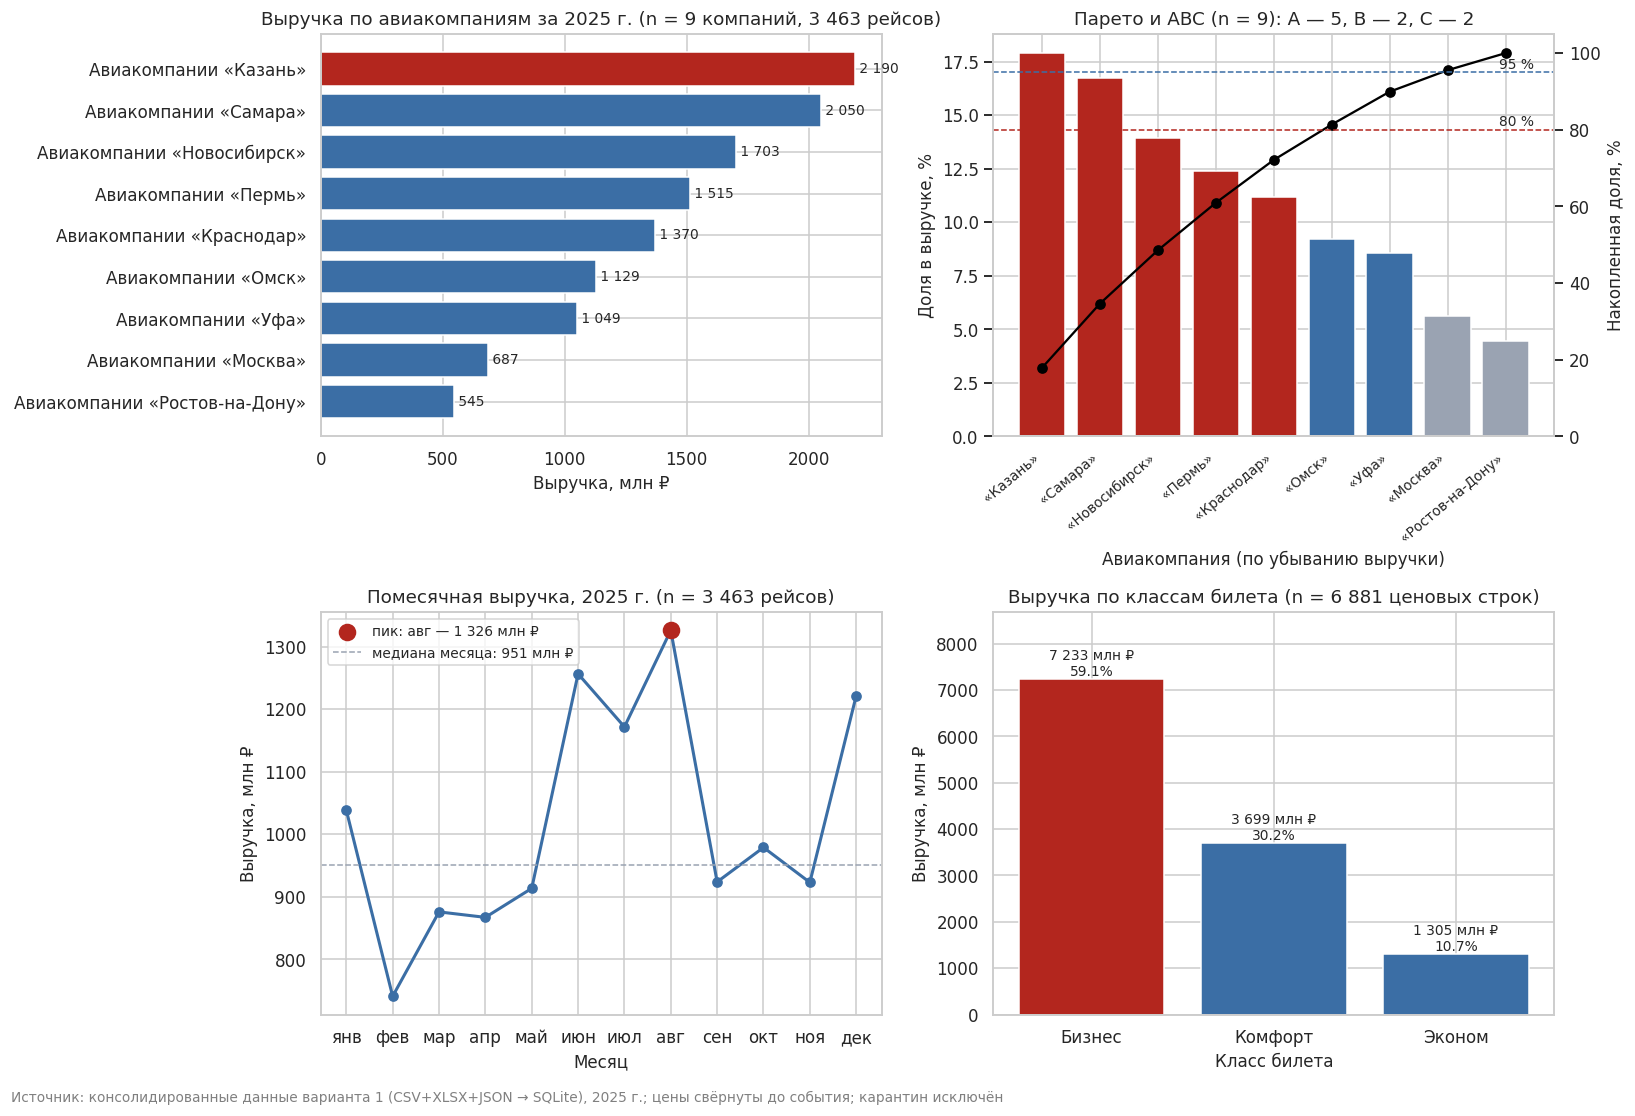

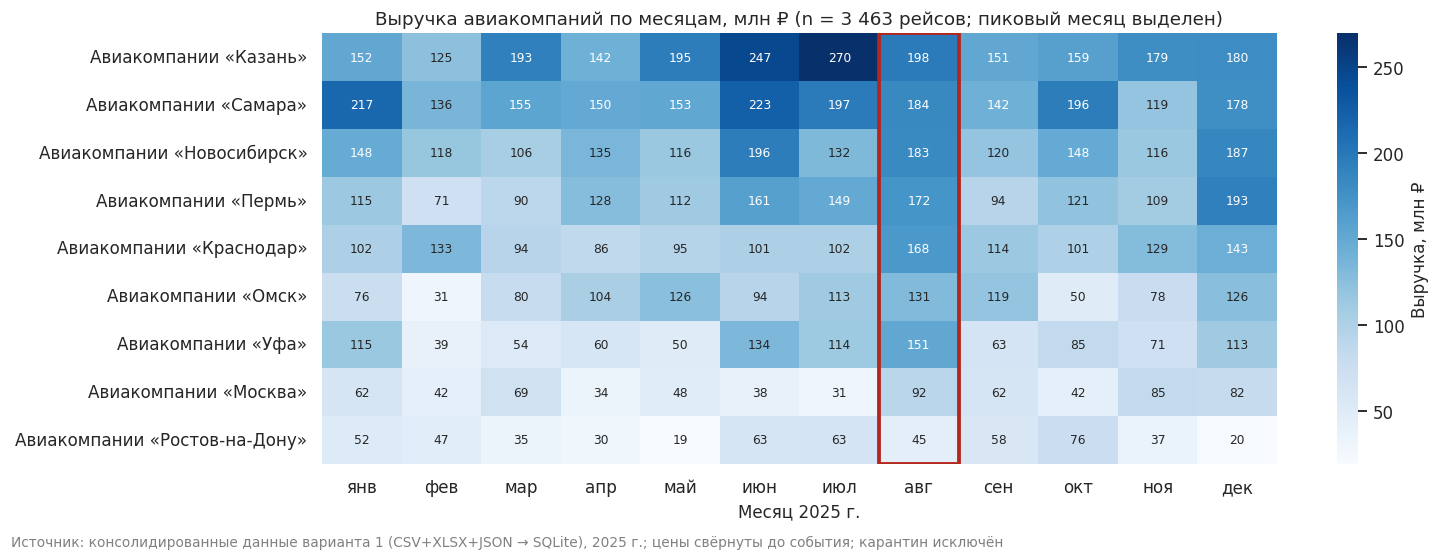

,entity_name,events_cnt,revenue,доля,накопленная доля,группа ABC
0,Авиакомпании «Казань»,612,"2,190,416,602.38",0.18,0.18,A
1,Авиакомпании «Самара»,573,"2,050,076,080.63",0.17,0.35,A
2,Авиакомпании «Новосибирск»,483,"1,703,046,832.21",0.14,0.49,A
3,Авиакомпании «Пермь»,429,"1,514,902,203.39",0.12,0.61,A
4,Авиакомпании «Краснодар»,383,"1,369,837,565.32",0.11,0.72,A
5,Авиакомпании «Омск»,332,"1,128,892,229.01",0.09,0.81,B
6,Авиакомпании «Уфа»,283,"1,048,769,428.53",0.09,0.90,B
7,Авиакомпании «Москва»,202,"686,746,954.34",0.06,0.96,C
8,Авиакомпании «Ростов-на-Дону»,166,"544,755,240.40",0.04,1.00,C


Витрина: mart_revenue_variant_1.xlsx (5 листов) и представление mart_revenue в consolidation_variant_1.sqlite; сумма по представлению: 12 237 443 136 ₽

================== ВЫВОДЫ ДЛЯ ЛПР — вариант 1, Авиаперевозки ==================
Данные: 9 авиакомпаний, 3 463 рейсов с ценой, 6 881 строк цен; в карантине
113 строк (1.1% исходных). Итоговая выручка: 12 237 443 136 ₽.

1. Сезонность. Пик — авг (1 326 млн ₽), минимум —
   фев (741 млн ₽), разрыв 1.79 раза.
   Лето (июнь–август) даёт 30.7% годовой выручки при 25 % календаря.
2. Кто формирует пик: в авг лидируют
   Авиакомпании «Казань» — 15%; Авиакомпании «Самара» — 14%; Авиакомпании «Новосибирск» — 14%
   (вместе 43% выручки пикового месяца).
3. Концентрация. Лидер года — Авиакомпании «Казань» (17.9%), топ-3 — 49%;
   в группе A 5 из 9 компаний.
4. Структура: класс «Бизнес» даёт 59% выручки.
5. Качество данных: наивный JOIN завышал выручку в 1.98 раза; SQL и pandas сошлись (Δ = 0.0050 ₽).

Рекомендации:
 • Планировать провозные ёмкости 

In [7]:
#@title Шаг 6. Аналитика и визуализация (задание) { display-mode: "form" }
ACCENT, BASE, GREY = "#b3261e", "#3b6ea5", "#9aa3b2"
RU_MONTHS = ["янв", "фев", "мар", "апр", "май", "июн", "июл", "авг", "сен", "окт", "ноя", "дек"]
total_revenue = float(revenue_sql["revenue"].sum())
N_EV, N_ENT = len(consolidated), len(revenue_sql)
mln = lambda x: x / 1e6

# ---------------------------------------------------------------- срезы
pareto = revenue_sql.sort_values("revenue", ascending=False).reset_index(drop=True)
pareto["доля"] = pareto["revenue"] / total_revenue
pareto["накопленная доля"] = pareto["доля"].cumsum()
# ABC по накопленной доле: A — до 80 % включительно, B — до 95 %, C — остальное
cum = pareto["накопленная доля"].round(10)
pareto["группа ABC"] = np.select([cum <= 0.80, cum <= 0.95], ["A", "B"], "C")

consolidated["month"] = consolidated["event_date"].dt.month
monthly = (consolidated.groupby("month", as_index=False)
           .agg(revenue=("event_revenue", "sum"), events=("event_id", "count"),
                passengers=("volume_units", "sum")))
peak = monthly.loc[monthly["revenue"].idxmax()]
low = monthly.loc[monthly["revenue"].idxmin()]

# выручка события делится между его ценовыми строками поровну: так сумма по классам = итогу
by_class = (prices_valid.merge(consolidated[["event_id", "volume_units", "price_rows"]], on="event_id")
            .assign(revenue=lambda d: d["volume_units"] * d["unit_price"] / d["price_rows"])
            .groupby("price_class", as_index=False)["revenue"].sum()
            .sort_values("revenue", ascending=False))

# кто формирует пиковый месяц (аналитическая задача варианта 1)
peak_by_company = (consolidated[consolidated["month"] == peak["month"]]
                   .groupby("entity_name")["event_revenue"].sum().sort_values(ascending=False))

# ---------------------------------------------------------------- контроль сходимости
recon = pd.DataFrame({
    "разрез": ["по субъектам (SQL)", "по месяцам", f"по разрезу «{CFG['cls']}»",
               "пиковый месяц по компаниям = пиковый месяц"],
    "сумма, ₽": [total_revenue, monthly["revenue"].sum(), by_class["revenue"].sum(), peak_by_company.sum()],
    "эталон, ₽": [total_revenue, total_revenue, total_revenue, peak["revenue"]],
})
recon["расхождение, ₽"] = (recon["сумма, ₽"] - recon["эталон, ₽"]).abs().round(2)
display(recon)
assert recon["расхождение, ₽"].max() < 1.0, "сумма по разрезу не сходится с итогом — повторный fan-out"

def foot(fig):
    fig.text(0.01, -0.01, f"Источник: консолидированные данные варианта {VARIANT} (CSV+XLSX+JSON → SQLite), "
             f"2025 г.; цены свёрнуты до события; карантин исключён", fontsize=9, color="gray")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Выручка по субъектам, лидер выделен
ax = axes[0, 0]
top = pareto.sort_values("revenue")
ax.barh(top["entity_name"], mln(top["revenue"]),
        color=[ACCENT if n == pareto.loc[0, "entity_name"] else BASE for n in top["entity_name"]])
for y, v in enumerate(mln(top["revenue"])):
    ax.text(v, y, f" {v:,.0f}".replace(",", " "), va="center", fontsize=9)
ax.set(title=f"Выручка по авиакомпаниям за 2025 г. (n = {N_ENT} компаний, {nf(N_EV)} рейсов)",
       xlabel="Выручка, млн ₽", ylabel="")

# 2. Парето + ABC
ax = axes[0, 1]
x = np.arange(len(pareto))
ax.bar(x, pareto["доля"] * 100, color=pareto["группа ABC"].map({"A": ACCENT, "B": BASE, "C": GREY}))
ax.set_xticks(x, [n.replace(CFG["parent"] + " ", "") for n in pareto["entity_name"]],
              rotation=40, ha="right", fontsize=9)
ax.set(ylabel="Доля в выручке, %", xlabel="Авиакомпания (по убыванию выручки)")
ax2 = ax.twinx()
ax2.plot(x, pareto["накопленная доля"] * 100, color="black", marker="o", lw=1.5)
for thr in (80, 95):
    ax2.axhline(thr, color=ACCENT if thr == 80 else BASE, ls="--", lw=1)
    ax2.text(len(x) - 0.5, thr + 1, f"{thr} %", ha="right", fontsize=9)
ax2.set_ylim(0, 105); ax2.set_ylabel("Накопленная доля, %"); ax2.grid(False)
n_a = int((pareto["группа ABC"] == "A").sum()); n_b = int((pareto["группа ABC"] == "B").sum())
ax.set_title(f"Парето и ABC (n = {N_ENT}): A — {n_a}, B — {n_b}, C — {N_ENT - n_a - n_b}")

# 3. Сезонность
ax = axes[1, 0]
ax.plot(monthly["month"], mln(monthly["revenue"]), marker="o", color=BASE, lw=2)
ax.scatter(peak["month"], mln(peak["revenue"]), color=ACCENT, s=110, zorder=3,
           label=f"пик: {RU_MONTHS[int(peak['month']) - 1]} — {mln(peak['revenue']):,.0f} млн ₽".replace(",", " "))
ax.axhline(mln(monthly["revenue"].median()), color=GREY, ls="--", lw=1,
           label=f"медиана месяца: {mln(monthly['revenue'].median()):,.0f} млн ₽".replace(",", " "))
ax.set_xticks(range(1, 13), RU_MONTHS)
ax.set(title=f"Помесячная выручка, 2025 г. (n = {nf(N_EV)} рейсов)", xlabel="Месяц", ylabel="Выручка, млн ₽")
ax.legend(fontsize=9)

# 4. Структура по классам билета
ax = axes[1, 1]
ax.bar(by_class["price_class"], mln(by_class["revenue"]),
       color=[ACCENT if i == 0 else BASE for i in range(len(by_class))])
for i, v in enumerate(by_class["revenue"]):
    ax.text(i, mln(v), f"{mln(v):,.0f} млн ₽\n{v / total_revenue:.1%}".replace(",", " "),
            ha="center", va="bottom", fontsize=9)
ax.set(title=f"Выручка по классам билета (n = {nf(len(prices_valid))} ценовых строк)",
       xlabel="Класс билета", ylabel="Выручка, млн ₽")
ax.set_ylim(0, mln(by_class["revenue"].max()) * 1.2)
foot(fig); plt.tight_layout(); plt.show()

# 5. (доп.) Кто формирует выручку по месяцам: тепловая карта компания × месяц, доля месяца
heat = (consolidated.pivot_table(index="entity_name", columns="month", values="event_revenue", aggfunc="sum")
        .reindex(pareto["entity_name"]))
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(mln(heat), annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "Выручка, млн ₽"}, ax=ax,
            annot_kws={"fontsize": 8})
ax.set_xticklabels(RU_MONTHS)
ax.add_patch(plt.Rectangle((peak["month"] - 1, 0), 1, len(heat), fill=False, ec=ACCENT, lw=2.5))
ax.set(title=f"Выручка авиакомпаний по месяцам, млн ₽ (n = {nf(N_EV)} рейсов; пиковый месяц выделен)",
       xlabel="Месяц 2025 г.", ylabel="")
foot(fig); plt.tight_layout(); plt.show()
PLOTS_DONE = True

display(pareto[["entity_name", "events_cnt", "revenue", "доля", "накопленная доля", "группа ABC"]])

# ---------------------------------------------------------------- витрина: файл + представление в базе
mart = consolidated[["event_id", "entity_id", "entity_name", "region", "event_date", "month", D_COL, K_COL,
                     "volume_units", "price_rows", "avg_price", "event_revenue"]].copy()
MART_PATH = WORK / f"mart_revenue_variant_{VARIANT}.xlsx"
with pd.ExcelWriter(MART_PATH) as xw:
    mart.to_excel(xw, sheet_name="mart_events", index=False)
    pareto.to_excel(xw, sheet_name="by_entity_abc", index=False)
    monthly.to_excel(xw, sheet_name="by_month", index=False)
    by_class.to_excel(xw, sheet_name="by_class", index=False)
    clean_log_df.to_excel(xw, sheet_name="clean_log", index=False)
conn.execute("DROP VIEW IF EXISTS mart_revenue")
conn.execute(f"""CREATE VIEW mart_revenue AS
    WITH pe AS (SELECT event_id, AVG(unit_price) AS avg_price FROM prices GROUP BY event_id)
    SELECT ev.event_id, e.entity_name, ev.event_date, substr(ev.event_date, 1, 7) AS month,
           ev.volume_units, pe.avg_price, ev.volume_units * pe.avg_price AS event_revenue
    FROM events ev JOIN pe ON pe.event_id = ev.event_id JOIN entities e ON e.entity_id = ev.entity_id""")
conn.commit()
print(f"Витрина: {MART_PATH.name} (5 листов) и представление mart_revenue в {DB_PATH.name}; "
      f"сумма по представлению: {nf(conn.execute('SELECT SUM(event_revenue) FROM mart_revenue').fetchone()[0])} ₽")

# ------------------------------------------------------------------ TODO 6.2
leader = pareto.iloc[0]
top3_share = float(pareto["доля"].head(3).sum())
season_gap = float(peak["revenue"] / low["revenue"])
summer = monthly[monthly["month"].isin([6, 7, 8])]["revenue"].sum() / total_revenue
peak_top = peak_by_company.head(3)
q_total = len(quarantine_fk) + len(quarantine_volume) + len(quarantine_price) + len(quarantine_price_orphan)
print(f"""
================== ВЫВОДЫ ДЛЯ ЛПР — вариант {VARIANT}, {CFG['domain']} ==================
Данные: {N_ENT} авиакомпаний, {nf(N_EV)} рейсов с ценой, {nf(len(prices_valid))} строк цен; в карантине
{q_total} строк ({q_total / (len(raw_events) + len(raw_prices)):.1%} исходных). Итоговая выручка: {nf(total_revenue)} ₽.

1. Сезонность. Пик — {RU_MONTHS[int(peak['month']) - 1]} ({nf(mln(peak['revenue']))} млн ₽), минимум —
   {RU_MONTHS[int(low['month']) - 1]} ({nf(mln(low['revenue']))} млн ₽), разрыв {season_gap:.2f} раза.
   Лето (июнь–август) даёт {summer:.1%} годовой выручки при 25 % календаря.
2. Кто формирует пик: в {RU_MONTHS[int(peak['month']) - 1]} лидируют
   {'; '.join(f"{n} — {v / peak['revenue']:.0%}" for n, v in peak_top.items())}
   (вместе {peak_top.sum() / peak['revenue']:.0%} выручки пикового месяца).
3. Концентрация. Лидер года — {leader['entity_name']} ({leader['доля']:.1%}), топ-3 — {top3_share:.0%};
   в группе A {n_a} из {N_ENT} компаний.
4. Структура: класс «{by_class.iloc[0]['price_class']}» даёт {by_class.iloc[0]['revenue'] / total_revenue:.0%} выручки.
5. Качество данных: наивный JOIN завышал выручку в {overstate:.2f} раза; SQL и pandas сошлись (Δ = {delta:.4f} ₽).

Рекомендации:
 • Планировать провозные ёмкости и персонал по помесячному профилю: в {RU_MONTHS[int(peak['month']) - 1]}
   выручка на {peak['revenue'] / monthly['revenue'].median() - 1:.0%} выше медианного месяца. Эффект — меньше
   недопроданных/перегруженных рейсов; проверка — загрузка рейсов в пиковые месяцы следующего года.
 • Договоры о летних слотах и маркетинг пикового сезона фокусировать на компаниях группы A ({n_a} шт.):
   они формируют ~80 % выручки. Проверка — доля группы A в выручке июня–августа.
 • Закрепить методику «свёртка цен до рейса → объём × средняя цена» в регламенте отчётности и
   автопроверку сверки SQL/pandas: без неё отчёт завышен в {overstate:.1f} раза. Карантин ({q_total} строк)
   разбирать с владельцами источников. Проверка — Δ SQL/pandas < 1 ₽ и доля карантина в каждой загрузке.
=====================================================================================""")


**Интерпретация.** На диаграмме Парето смотрите, сколько субъектов попало в группу A: это и есть ответ на вопрос «где сосредоточено управленческое внимание». На сезонности сравните пик и провал: разрыв в полтора-два раза означает, что планирование по среднегодовому значению даст дефицит мощностей летом и простой зимой. В структуре по классам главное — строка контроля сходимости: ноль подтверждает, что при разрезании выручки вы не размножили её повторно.

Выводы для ЛПР — не пересказ графиков, а решения: что делать, на каком основании и как проверить результат.

### Выводы и рекомендации (вариант 1 — Авиаперевозки)

> ✏️ Числа взяты из прогона варианта 1: генерация детерминирована, поэтому у вас они должны совпасть. Сверьте с выводом шага 6 и удалите эту строку.

**Что сделано.** Три источника (авиакомпании — CSV, рейсы — XLSX, билеты — JSON) прочитаны как текст. Аудит нашёл **11 проблем по всем шести измерениям качества**: дубликат авиакомпании, имя в верхнем регистре с пробелами, пропуск региона, 11 рейсов с пропуском объёма, 13 объёмов строкой, 11 дат в формате дд.мм.гггг, 15 цен строкой с «₽», 15 пропусков и 16 отрицательных цен, 17 рейсов несуществующей компании E999, 304 рейса «город — тот же город». После очистки осталось 9 авиакомпаний, 3 472 рейса и 6 881 строка цен. В карантин ушло 113 строк (≈ 1,1 %), ни одна строка не удалена без записи в журнале, пропуски остались пропусками. База SQLite с PK, FK, `CHECK` и индексами сама отвергает «сироту» и отрицательную цену.

**Ключевой результат по качеству.** Связь «рейс → билеты» — 1 : N (в среднем 1,99 строки цены на рейс). Наивный `JOIN` завышает выручку в **K = 1,98 раза** (24,2 млрд ₽ вместо 12,24 млрд ₽). После свёртки цен до рейса SQL и pandas совпали с расхождением 0,005 ₽ (это округление). Суммы по субъектам, месяцам и классам билета сходятся с итогом до копейки.

**Наблюдения.**
1. **Сезонность:** пик выручки — **август (1 326 млн ₽)**, минимум — февраль (741 млн ₽), разрыв 1,79 раза. На июнь–август приходится 30,7 % годовой выручки при 25 % календаря; второй всплеск — декабрь.
2. **Кто формирует пик:** в августе лидируют «Казань» (15 %), «Самара» (14 %) и «Новосибирск» (14 %), вместе 43 % выручки месяца. Тепловая карта показывает, что август — пиковый месяц и для компаний второго эшелона («Уфа», «Москва», «Краснодар»): пик общий, а не создан одним перевозчиком.
3. **Концентрация:** лидер года — «Казань» (17,9 %), топ-3 — 49 %. В группу A (до 80 % выручки) входят 5 из 9 компаний.
4. **Структура:** класс «Бизнес» даёт 59 % выручки, «Эконом» — около 11 %.

**Рекомендации.**
1. **Планировать ёмкость и персонал по помесячному профилю**, а не по среднему году: в августе выручка на ~39 % выше медианного месяца. *Эффект:* меньше перегруженных и недозаполненных рейсов. *Проверка:* загрузка кресел и отказы в продаже в июне–августе следующего года.
2. **Летние слоты, допрейсы и сезонный маркетинг согласовывать в первую очередь с компаниями группы A**: они формируют ~80 % выручки и ~43 % пика (топ-3). *Эффект:* максимальный прирост выручки на единицу усилий. *Проверка:* доля группы A в выручке июня–августа по сравнению с текущим годом.
3. **Закрепить методику расчёта** «свёртка цен до рейса → объём × средняя цена» и автотесты качества (см. задание со звёздочкой) в регламенте отчётности. Без этого отчёт завышен вдвое. *Проверка:* при каждой загрузке Δ SQL/pandas < 1 ₽, доля карантина < 2 %, разбор карантина с владельцами источников.

**Ограничения.** Данные учебные и сгенерированы за один год (2025), поэтому сезонность — один цикл без сравнения с прошлыми годами. Средняя цена рейса — простое среднее по классам: без числа проданных билетов каждого класса выручка «Бизнеса» может быть завышена. Объём (пассажиры) не разбит по классам. 304 маршрута с совпадающими городами отмечены, но не исправлены: на выручку не влияют, их нужно уточнить у владельца данных.


## Шаг 7. BigQuery: пошаговое подключение из Colab

Показать, как та же витрина переносится в облачное хранилище, когда данных становится слишком много для одной машины.

### Шаг 1. Аккаунт и проект

1. Откройте <https://console.cloud.google.com> и войдите в аккаунт Google.
2. Вверху нажмите селектор проектов → **New Project**, задайте имя (например, `pw2-consolidation`) и создайте проект.
3. Скопируйте **Project ID** — это не название, а идентификатор вида `pw2-consolidation-123456`. Он понадобится в коде.

### Шаг 2. Режим работы: sandbox или биллинг

* **BigQuery sandbox** — без привязки карты. Бесплатно: 10 ГБ хранения и 1 ТБ обработанных запросами данных в месяц. Ограничения: нет DML-операций в части сценариев, таблицы автоматически удаляются через 60 дней. Для этой работы sandbox достаточно.
* **С биллингом** — снимаются ограничения sandbox, бесплатные лимиты те же. Карта привязывается в разделе **Billing**.

### Шаг 3. Включение API

В консоли: **APIs & Services → Library → BigQuery API → Enable**. Без этого библиотека вернёт ошибку доступа.

### Шаг 4. Аутентификация в Colab

```python
from google.colab import auth
auth.authenticate_user()     # откроется окно входа в Google-аккаунт
```

Вне Colab используется либо `gcloud auth application-default login`, либо ключ сервисного аккаунта: **IAM & Admin → Service Accounts → Create** → роль **BigQuery Data Editor** и **BigQuery Job User** → **Keys → Add key (JSON)**. Путь к файлу ключа кладётся в переменную окружения `GOOGLE_APPLICATION_CREDENTIALS`.

> Файл ключа — это пароль от проекта. Его нельзя коммитить в репозиторий и нельзя оставлять в выводе ячейки.

### Шаг 5. Датасет

Датасет — контейнер таблиц с привязкой к региону (`US`, `EU`, `europe-west3`). Регион выбирается один раз: соединять таблицы из разных регионов нельзя. Создаётся кодом в ячейке ниже (`create_dataset(..., exists_ok=True)`) или в консоли кнопкой **Create dataset**.

### Шаг 6. Загрузка и запрос

Код ячейки делает следующее:

1. загружает три очищенные таблицы через `load_table_from_dataframe` с режимом `WRITE_TRUNCATE` (перезапись — повторный запуск не плодит дубликаты);
2. выполняет **сухой прогон** (`dry_run=True`), который показывает, сколько байт прочитает запрос, ничего не тратя, — привычка, экономящая бюджет;
3. выполняет тот же корректный расчёт выручки, что и в SQLite;
4. сверяет результат с SQLite: цифры обязаны совпасть.

### Шаг 7. Стоимость и правила экономии

Оплата в BigQuery берётся за **объём прочитанных данных**, а не за время. Отсюда практические правила:

* не писать `SELECT *` — читаются только перечисленные колонки (колоночное хранение);
* использовать партиционирование по дате и кластеризацию по ключу фильтрации;
* перед тяжёлым запросом делать `dry_run`;
* учебные наборы этой работы весят единицы мегабайт, то есть укладываются в бесплатный лимит с огромным запасом.

### Отличия синтаксиса от SQLite

| | SQLite | BigQuery (GoogleSQL) |
|---|---|---|
| Идентификаторы | `"table"` или без кавычек | `` `project.dataset.table` `` |
| Типы дат | текст `YYYY-MM-DD` | `DATE`, `TIMESTAMP` |
| Приведение типа | `CAST(x AS REAL)` | `CAST(x AS FLOAT64)`, `SAFE_CAST` |
| Ключи | `PRIMARY KEY`, `FOREIGN KEY` | ограничения не проверяются: целостность обеспечивает конвейер |
| Пагинация | `LIMIT n OFFSET m` | `LIMIT n OFFSET m`, но для больших выборок — экспорт |

Последняя строка таблицы — важный профессиональный вывод: в аналитических хранилищах контроль качества не делегируется базе. Всё, что вы сделали на шагах 3–4, в промышленном контуре становится обязательным этапом конвейера.

In [8]:
#@title Шаг 7. Выгрузка витрины в BigQuery { display-mode: "form" }
# Ячейка ничего не делает, пока ENABLE_BIGQUERY = False в шаге 1.
# Перед включением выполните шаги из markdown-инструкции выше: проект, sandbox, датасет.
BQ_PROJECT_ID = "my-gcp-project"   #@param {type:"string"}
BQ_DATASET = "pw2_consolidation"   #@param {type:"string"}
BQ_LOCATION = "US"                 #@param ["US", "EU", "europe-west3", "asia-northeast1"]

if not ENABLE_BIGQUERY:
    print("BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: "
          "основная часть работы выполняется на SQLite.")
else:
    ensure("google-cloud-bigquery", "google.cloud.bigquery")
    ensure("pandas-gbq", "pandas_gbq")
    from google.cloud import bigquery

    # 1. Аутентификация: в Colab открывает окно входа в Google-аккаунт
    try:
        from google.colab import auth
        auth.authenticate_user()
        print("Аутентификация в Colab выполнена")
    except ImportError:
        print("Не Colab: используйте `gcloud auth application-default login` "
              "или переменную GOOGLE_APPLICATION_CREDENTIALS с путём к ключу сервисного аккаунта")

    client = bigquery.Client(project=BQ_PROJECT_ID, location=BQ_LOCATION)

    # 2. Датасет создаётся, если его ещё нет
    dataset_ref = bigquery.Dataset(f"{BQ_PROJECT_ID}.{BQ_DATASET}")
    dataset_ref.location = BQ_LOCATION
    client.create_dataset(dataset_ref, exists_ok=True)
    print(f"Датасет готов: {BQ_PROJECT_ID}.{BQ_DATASET} ({BQ_LOCATION})")

    # 3. Загрузка трёх очищенных таблиц
    for name, frame in [("entities", entities),
                        ("events", events_out),
                        ("prices", prices_valid[["price_id", "event_id", "unit_price", "price_class"]])]:
        job = client.load_table_from_dataframe(
            frame, f"{BQ_PROJECT_ID}.{BQ_DATASET}.{name}",
            job_config=bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE"))
        job.result()
        print(f"  загружено {name}: {nf(len(frame))} строк")

    # 4. Тот же корректный расчёт выручки, но на стороне BigQuery
    bq_sql = f"""
    WITH price_per_event AS (
        SELECT event_id, AVG(unit_price) AS avg_price
        FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.prices`
        GROUP BY event_id
    )
    SELECT e.entity_name,
           COUNT(ev.event_id)                            AS events_cnt,
           ROUND(SUM(ev.volume_units * pe.avg_price), 2) AS revenue
    FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.entities` e
    JOIN `{BQ_PROJECT_ID}.{BQ_DATASET}.events` ev ON ev.entity_id = e.entity_id
    JOIN price_per_event pe ON pe.event_id = ev.event_id
    GROUP BY e.entity_name
    ORDER BY revenue DESC
    """

    # 5. Сухой прогон: сколько байт прочитает запрос (в sandbox бесплатно 1 ТБ в месяц)
    dry = client.query(bq_sql, job_config=bigquery.QueryJobConfig(dry_run=True, use_query_cache=False))
    print(f"\nОценка объёма чтения: {dry.total_bytes_processed / 1024**2:.2f} МБ "
          f"(бесплатный лимит — 1 ТБ в месяц)")

    revenue_bq = client.query(bq_sql).to_dataframe()
    display(revenue_bq.head(10))

    # 6. Сверка с SQLite: цифры обязаны совпасть
    check = (revenue_bq.set_index("entity_name")["revenue"]
             - revenue_sql.set_index("entity_name")["revenue"]).abs().max()
    print(f"Максимальное расхождение BigQuery и SQLite: {check:.4f}")

BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: основная часть работы выполняется на SQLite.


## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель; он подставляется в поле `VARIANT` шага 1 и определяет предметную область, объём генерации и набор дефектов (столбец «Дефекты»: ★ — базовый набор, ★★ — добавляются битые внешние ключи и отрицательные цены, ★★★ — ещё и дубликаты записей).

Архитектура данных во всех вариантах одинакова: справочник субъектов (CSV) → события с объёмом (XLSX) → цены по событиям, несколько строк на событие (JSON). Считается выручка по субъектам.

| № | Предметная область | CSV: справочник | XLSX: события | JSON: цены | Единица объёма | Разрез цен | Аналитическая задача | Дефекты |
|---:|---|---|---|---|---|---|---|:--:|
| 1 | Авиаперевозки | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют | ★★ |
| 2 | Розничная сеть | Магазины | Чеки | Позиции чека | единиц товара | категория товара | ABC-анализ магазинов: какие точки дают 80 % выручки | ★★★ |
| 3 | Логистика | Перевозчики | Отгрузки | Тарифы | паллет | тип тарифа | Загрузка перевозчиков: связь объёма и средней ставки | ★ |
| 4 | Телеком | Операторы | Сессии связи | Тарификация | минут | тарифный план | Доля тарифных планов в выручке и средний чек сессии | ★★ |
| 5 | Банковский ритейл | Отделения | Операции | Комиссии | транзакций | тип комиссии | Эффективность отделений: выручка на одну операцию | ★★★ |
| 6 | Гостиничный бизнес | Отели | Бронирования | Тарифы номеров | ночей | категория номера | Сезонность загрузки и вклад категорий номеров | ★ |
| 7 | Образовательные услуги | Центры | Группы | Стоимость обучения | слушателей | формат обучения | Выручка на слушателя и сравнение форматов | ★★ |
| 8 | Медицинские клиники | Клиники | Приёмы | Прейскурант | пациентов | вид услуги | Структура выручки по видам услуг и загрузка клиник | ★★★ |
| 9 | Энергосбыт | Сбытовые компании | Поставки | Тарифы | МВт·ч | категория потребителя | Концентрация выручки по категориям потребителей | ★ |
| 10 | Маркетплейс | Продавцы | Заказы | Цены товаров | единиц | категория товара | Топ продавцов и доля категорий в обороте | ★★ |
| 11 | Общественный транспорт | Перевозчики | Маршруты-рейсы | Тарифы проезда | пассажиров | тип билета | Выручка по типам билетов и пиковые месяцы | ★★★ |
| 12 | Страхование | Агентства | Договоры | Тарифные ставки | объектов | вид страхования | Средняя премия по видам страхования и вклад агентств | ★ |
| 13 | Грузовые ж/д перевозки | Операторы вагонов | Отправки | Ставки | тонн | род груза | Доходность по родам груза и сезонность отправок | ★★ |
| 14 | Общепит | Рестораны | Заказы | Цены блюд | порций | категория меню | Средний чек и вклад категорий меню | ★★★ |
| 15 | Фитнес-сети | Клубы | Визиты и покупки | Прайс услуг | услуг | тип абонемента | Выручка на клуб и структура абонементов | ★ |
| 16 | Аренда спецтехники | Парки техники | Смены аренды | Ставки аренды | машино-часов | тип техники | Утилизация парка и доходность типов техники | ★★ |
| 17 | Курьерская доставка | Службы доставки | Доставки | Тарифы | посылок | скорость доставки | Доля экспресс-доставки в выручке | ★★★ |
| 18 | Оптовая торговля | Дистрибьюторы | Поставки | Прайс-листы | коробов | товарная группа | Парето по товарным группам и вклад дистрибьюторов | ★ |
| 19 | Автосервис | Сервисные центры | Заказ-наряды | Прейскурант работ | нормо-часов | вид работ | Выручка по видам работ и загрузка центров | ★★ |
| 20 | Цифровые подписки | Сервисы | Подписки | Тарифные планы | подписчиков | план подписки | Структура подписной базы и выручка на подписчика | ★★★ |
| 21 | Сельхозпроизводство | Хозяйства | Партии отгрузки | Закупочные цены | тонн | культура | Доходность культур и сезонность отгрузок | ★ |
| 22 | Строительный ритейл | Гипермаркеты | Продажи | Цены материалов | единиц | группа материалов | Сезонность продаж и вклад групп материалов | ★★ |
| 23 | Морские перевозки | Судоходные линии | Рейсы судов | Фрахтовые ставки | TEU | тип контейнера | Доходность линий и структура по типам контейнеров | ★★★ |
| 24 | Аптечные сети | Аптеки | Продажи | Цены препаратов | упаковок | группа препаратов | Вклад товарных групп и сравнение точек | ★ |
| 25 | Кинотеатры | Кинотеатры | Сеансы | Цены билетов | зрителей | тип сеанса | Заполняемость залов и выручка по типам сеансов | ★★ |
| 26 | Промышленное производство | Заводы | Партии продукции | Отпускные цены | тонн | марка продукции | Вклад марок продукции и сезонность отгрузок | ★★★ |
| 27 | Рекламные площадки | Площадки | Кампании | Ставки размещения | показов (тыс.) | формат размещения | Доходность форматов и концентрация выручки | ★ |
| 28 | ЖКХ | Управляющие компании | Начисления | Тарифы услуг | объектов | вид услуги | Структура начислений и сравнение управляющих компаний | ★★ |
| 29 | Каршеринг | Операторы | Поездки | Тарифы поездок | минут | класс автомобиля | Выручка на поездку и вклад классов автомобилей | ★★★ |
| 30 | Авиаперевозки (эталон преподавателя) | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки | ★ |

Минимум для зачёта: найдено не менее пяти проблем качества, заполнен журнал очистки, показана разница наивного и корректного расчёта, результаты SQL и pandas сошлись.

### Описательные столбцы событий и классы цен по вариантам

| № | Предметная область | Столбцы `events.xlsx` (кроме ключей, даты и объёма) | Классы цен в `prices.json` |
|---:|---|---|---|
| 1 | Авиаперевозки | `route`: «город — город»; `aircraft_type`: Узкофюзеляжный, Широкофюзеляжный, Региональный, Турбовинтовой | Эконом, Комфорт, Бизнес |
| 2 | Розничная сеть | `payment_method`: Наличные, Банковская карта, СБП, Карта + бонусы; `checkout_type`: Касса, Касса самообслуживания, Онлайн-заказ, Экспресс-касса | Бакалея, Бытовая химия, Электроника |
| 3 | Логистика | `route`: «город — город»; `vehicle_type`: Фура 20 т, Рефрижератор, Малотоннажный, Контейнеровоз | Базовый, Срочный, Экспресс |
| 4 | Телеком | `network`: 2G, 3G, 4G, 5G; `session_type`: Голос, Мобильный интернет, Роуминг, SMS-пакет | Базовый, Безлимитный, Корпоративный |
| 5 | Банковский ритейл | `service_channel`: Касса, Банкомат, Интернет-банк, Мобильное приложение; `client_segment`: Массовый, Зарплатный, Премиальный, МСБ | Переводы, Валютные операции, Инкассация |
| 6 | Гостиничный бизнес | `booking_channel`: Сайт отеля, Онлайн-агрегатор, Турагентство, Корпоративный договор; `guest_type`: Деловой, Туристический, Семейный, Групповой | Стандарт, Делюкс, Люкс |
| 7 | Образовательные услуги | `course_area`: IT, Иностранные языки, Управление, Подготовка к экзаменам; `audience`: Школьники, Студенты, Взрослые, Корпоративные клиенты | Онлайн, Смешанный, Очный |
| 8 | Медицинские клиники | `specialty`: Терапия, Педиатрия, Стоматология, Кардиология …; `payment_type`: ОМС, ДМС, Платно, Абонемент | Консультация, Диагностика, Процедура |
| 9 | Энергосбыт | `voltage_level`: ВН, СН-1, СН-2, НН; `contract_type`: Энергоснабжение, Купля-продажа, Регулируемый, Свободный рынок | Население, Бюджетные организации, Промышленность |
| 10 | Маркетплейс | `fulfillment`: Склад площадки, Склад продавца, Экспресс-доставка, Самовывоз; `order_channel`: Мобильное приложение, Сайт, Партнёрский сайт, Реклама в соцсетях | Товары для дома, Одежда, Электроника |
| 11 | Общественный транспорт | `line`: Маршрут 1, Маршрут 5, Маршрут 12, Маршрут 18 …; `vehicle_type`: Автобус, Трамвай, Троллейбус, Электробус | Разовый, Проездной на месяц, Проездной на год |
| 12 | Страхование | `client_type`: Физическое лицо, ИП, Малый бизнес, Крупный бизнес; `sales_channel`: Офис агентства, Онлайн, Банк-партнёр, Автосалон | ОСАГО, Имущество, КАСКО |
| 13 | Грузовые ж/д перевозки | `route`: «город — город»; `wagon_type`: Полувагон, Крытый вагон, Цистерна, Платформа | Уголь, Зерно, Нефтепродукты |
| 14 | Общепит | `service_format`: В зале, Навынос, Доставка, Банкет; `daypart`: Завтрак, Обед, Ужин, Поздний вечер | Напитки, Основные блюда, Фирменные сеты |
| 15 | Фитнес-сети | `visit_zone`: Тренажёрный зал, Бассейн, Групповые программы, Единоборства; `client_type`: Новый клиент, Постоянный, Корпоративный, Гостевой визит | Разовый, Месячный, Годовой |
| 16 | Аренда спецтехники | `site_type`: Жилое строительство, Дорожные работы, Промышленный объект, Коммунальные работы; `rental_mode`: С оператором, Без оператора, Долгосрочная, Почасовая | Мини-погрузчик, Экскаватор, Автокран |
| 17 | Курьерская доставка | `route`: «город — город»; `parcel_size`: Документы, Малая (S), Средняя (M), Крупная (L) | Стандарт, Ускоренная, Экспресс |
| 18 | Оптовая торговля | `client_channel`: Розничные сети, HoReCa, Независимая розница, Онлайн-ретейл; `delivery_mode`: Доставка дистрибьютора, Самовывоз, Транзит со склада, Кросс-докинг | Бакалея, Напитки, Кондитерские изделия |
| 19 | Автосервис | `car_class`: Отечественный, Иномарка эконом, Иномарка бизнес, Коммерческий транспорт; `visit_reason`: Плановое ТО, Ремонт, Шиномонтаж, Диагностика | Слесарные работы, Электрика и диагностика, Кузовные работы |
| 20 | Цифровые подписки | `platform`: iOS, Android, Веб, Smart TV; `acquisition`: Органика, Реклама, Промокод, Партнёр | Базовый, Стандарт, Премиум |
| 21 | Сельхозпроизводство | `buyer_type`: Элеватор, Перерабатывающий завод, Экспорт, Трейдер; `transport`: Автотранспорт, Железная дорога, Речной транспорт, Самовывоз | Пшеница, Подсолнечник, Соя |
| 22 | Строительный ритейл | `sales_channel`: Торговый зал, Интернет-магазин, Отдел для профи, Самовывоз со склада; `client_type`: Частный клиент, Бригада, Строительная компания, Дизайнер | Крепёж и расходники, Отделочные материалы, Инструмент |
| 23 | Морские перевозки | `route`: «порт — порт»; `cargo_mode`: Импорт, Экспорт, Транзит, Каботаж | 20' стандартный, 40' стандартный, 40' рефрижератор |
| 24 | Аптечные сети | `sales_channel`: Торговый зал, Онлайн-бронирование, Доставка, Корпоративный заказ; `shift`: Утренняя смена, Дневная смена, Вечерняя смена, Ночная смена | Безрецептурные (OTC), Рецептурные (Rx), Специализированная терапия |
| 25 | Кинотеатры | `hall`: Зал 1, Зал 2, Зал 3, Зал 4 …; `genre`: Анимация, Драма, Комедия, Фантастика | 2D, 3D, IMAX |
| 26 | Промышленное производство | `customer_type`: Дилер, Прямой клиент, Экспорт, Госзаказ; `shipping`: Железная дорога, Автотранспорт, Самовывоз, Контейнер | Марка М1, Марка М2, Марка М3 (премиум) |
| 27 | Рекламные площадки | `audience_age`: 18–24, 25–34, 35–44, 45+; `device`: Смартфон, Компьютер, Smart TV, Планшет | Баннер, Нативный, Видео |
| 28 | ЖКХ | `building_type`: Панельный дом, Кирпичный дом, Монолит, Новостройка; `payment_channel`: Банк, Госуслуги, Приложение УК, Касса УК | Содержание жилья, Водоснабжение, Отопление |
| 29 | Каршеринг | `trip_zone`: Центр, Спальный район, Аэропорт, Межгород; `client_type`: Новый, Постоянный, Корпоративный, Студенческий | Эконом, Комфорт, Премиум |
| 30 | Авиаперевозки (эталон преподавателя) | `route`: «город — город»; `aircraft_type`: Узкофюзеляжный, Широкофюзеляжный, Региональный, Турбовинтовой | Эконом, Комфорт, Бизнес |

## Критерии оценивания (10 баллов)

| Блок | Что проверяется | Максимум |
|---|---|---:|
| 1. Источники и загрузка | Три формата прочитаны корректно, без потери ведущих нулей и «умного» приведения типов | 1,0 |
| 2. Аудит качества | Профиль источников; журнал проблем по шести измерениям с числом затронутых строк; расчёт кардинальности связей | 2,0 |
| 3. Очистка | Журнал изменений; карантин вместо тихого удаления; пропуски не заменены нулями; разбор обоих форматов дат и чисел с валютой | 2,0 |
| 4. Модель данных и SQL | Схема с PK, FK, `CHECK` и индексами; `PRAGMA foreign_keys`; корректный запрос с CTE; сверка SQL и pandas | 2,5 |
| 5. Аналитика и визуализация | Четыре среза по варианту; контроль сходимости срезов; оформление графиков | 1,5 |
| 6. Выводы | Решения с основанием, ожидаемым эффектом и способом проверки; названы ограничения данных | 1,0 |

### Шкала

| Баллы | Оценка |
|---|---|
| 9–10 | **A** — конвейер воспроизводим, качество данных проработано, выводы управленческие |
| 8–9 | **B** — данные консолидированы верно, есть недочёты в аудите или оформлении |
| 7–8 | **C** — расчёт верен, но качество данных проработано формально |
| 6–7 | **D** — есть результат, но методика расчёта или очистки содержит ошибки |
| < 6 | **F** — выручка посчитана наивным JOIN, дефекты не найдены, работа не воспроизводится |

### Обязательные требования

1. Расчёт выручки выполнен **после** свёртки цен до уровня события; коэффициент завышения наивного варианта показан числом.
2. Результаты SQL и pandas сходятся с точностью округления.
3. Ни одна строка не удалена без записи в журнале очистки.
4. Пропуски остались пропусками.
5. Все графики подписаны: заголовок с объёмом выборки, оси с единицами измерения.
6. Сумма по любому аналитическому разрезу совпадает с итоговой выручкой.

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Выручка посчитана наивным соединением, эффект fan-out не обнаружен | −2,5 |
| `NaN` заменены нулями «чтобы считалось» | −1,0 |
| Строки удалены без журнала и карантина | −1,0 |
| Нет внешних ключей и ограничений в схеме | −1,0 |
| Расхождение SQL и pandas не объяснено | −1,0 |
| Графики без подписей осей и единиц | −0,5 |
| Ноутбук сдан без выводов ячеек | −1,0 |
| Ключ сервисного аккаунта Google в репозитории | −1,5 и обязательный отзыв ключа |

In [9]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []
def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Вариант выбран корректно", 1 <= VARIANT <= 30)
check("Созданы три источника разных форматов",
      all((DATA / f).exists() for f in ("entities.csv", "events.xlsx", "prices.json")))
check("Проведён аудит качества (журнал не пуст)", len(globals().get("issues", [])) >= 5,
      "найдите проблемы по всем шести измерениям качества")
check("Журнал очистки заполнен", len(globals().get("CLEAN_LOG", [])) >= 4)
check("Пропуски не заменены нулями",
      float(events_valid["volume_units"].min()) > 0 and float(prices_valid["unit_price"].min()) > 0)
check("Нарушения целостности вынесены в карантин, а не удалены молча",
      "quarantine_fk" in globals() and "quarantine_price" in globals())
check("База SQLite создана и заполнена", DB_PATH.exists() and DB_PATH.stat().st_size > 20000)
check("Внешние ключи и ограничения объявлены",
      "REFERENCES" in "".join(r[0] for r in conn.execute(
          "SELECT sql FROM sqlite_master WHERE type='table'").fetchall() if r[0]))
check("Показана разница наивного и корректного расчёта", globals().get("overstate", 0) > 1.05,
      "наивный JOIN обязан завышать выручку — покажите это числом")
check("SQL и pandas сошлись", globals().get("delta", 1e9) < 1.0,
      "расхождение больше рубля означает разную методику расчёта")
check("Построены графики", len(plt.get_fignums()) > 0 or globals().get("PLOTS_DONE", False))

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))

Выполнено: 11 из 11

  ✅ Вариант выбран корректно
  ✅ Созданы три источника разных форматов
  ✅ Проведён аудит качества (журнал не пуст)
  ✅ Журнал очистки заполнен
  ✅ Пропуски не заменены нулями
  ✅ Нарушения целостности вынесены в карантин, а не удалены молча
  ✅ База SQLite создана и заполнена
  ✅ Внешние ключи и ограничения объявлены
  ✅ Показана разница наивного и корректного расчёта
  ✅ SQL и pandas сошлись
  ✅ Построены графики


## Задание со звёздочкой (до +2 баллов)

Учебная витрина собирается один раз. Промышленная — обновляется, хранит историю и проверяет себя сама. Выберите одно направление и доведите до измеримого результата.

In [10]:
#@title Задание со звёздочкой — C. Автотесты качества данных { display-mode: "form" }
# A. Инкрементальная загрузка.
#    Сгенерируйте «следующий день» данных и реализуйте догрузку через UPSERT
#    (INSERT ... ON CONFLICT DO UPDATE) вместо полной перезаписи. Покажите, что повторный
#    запуск не создаёт дубликатов (идемпотентность).
#
# B. Медленно меняющиеся измерения (SCD Type 2).
#    Субъект сменил название. Реализуйте историчность справочника (valid_from, valid_to, is_current)
#    и покажите, что выручка прошлых периодов осталась привязана к прежнему названию.
#
# C. Автотесты качества данных.
#    Оформите проверки шага 3 как набор тестов (assert или pytest), которые запускаются
#    при каждой загрузке и останавливают конвейер при падении критичных правил.
#
# D. Взвешенная цена вместо средней.
#    Сейчас цены сворачиваются простым средним. Если известно число проданных единиц по классам,
#    корректнее взвешенное среднее. Реализуйте и покажите, как меняется выручка и почему.
#
# E. Сравнение движков.
#    Замерьте время корректного расчёта на pandas, SQLite и (если включали) BigQuery
#    при объёме в 10 раз больше. Постройте график и объясните, где проходит граница применимости.

# Проверки шага 3 оформлены как правила, которые запускаются при каждой загрузке.
# Критичные правила (severity="critical") останавливают конвейер, предупреждения — только пишутся в лог.
class DataQualityError(Exception):
    pass

def dq_rules(ent, ev, pr):
    """Набор правил: (название, критичность, число нарушений)."""
    num = lambda x: x if pd.api.types.is_numeric_dtype(x) else to_number(x)
    ev_num, pr_num = num(ev["volume_units"]), num(pr["unit_price"])
    ev_date = (ev["event_date"] if pd.api.types.is_datetime64_any_dtype(ev["event_date"])
               else to_date(ev["event_date"]))
    return [
        ("PK entities уникален",            "critical", int(ent["entity_id"].duplicated().sum())),
        ("PK events уникален",              "critical", int(ev["event_id"].duplicated().sum())),
        ("PK prices уникален",              "critical", int(pr["price_id"].duplicated().sum())),
        ("FK events → entities",            "critical", int((~ev["entity_id"].isin(ent["entity_id"])).sum())),
        ("FK prices → events",              "critical", int((~pr["event_id"].isin(ev["event_id"])).sum())),
        ("объём > 0 и не пуст",             "critical", int((~(ev_num > 0)).sum())),
        ("цена > 0 и не пуста",             "critical", int((~(pr_num > 0)).sum())),
        ("дата распознана",                 "critical", int(ev_date.isna().sum())),
        ("цены не размножают события (≤ 3 строк)", "warning", int((pr.groupby("event_id").size() > 3).sum())),
        ("регион субъекта заполнен",        "warning",  int(ent["region"].isna().sum())),
    ]

def run_dq(ent, ev, pr, stage):
    res = pd.DataFrame(dq_rules(ent, ev, pr), columns=["правило", "критичность", "нарушений"])
    res["статус"] = np.where(res["нарушений"] == 0, "PASS",
                             np.where(res["критичность"] == "critical", "FAIL", "WARN"))
    print(f"\n— {stage}: PASS {sum(res['статус'] == 'PASS')}, WARN {sum(res['статус'] == 'WARN')}, "
          f"FAIL {sum(res['статус'] == 'FAIL')}")
    display(res)
    fails = res[res["статус"] == "FAIL"]
    if len(fails):
        raise DataQualityError(f"{stage}: конвейер остановлен, нарушены правила: {', '.join(fails['правило'])}")
    return res

# 1) Сырые данные: тесты обязаны остановить загрузку
try:
    run_dq(raw_entities, raw_events, raw_prices, "Сырые источники")
    raw_blocked = False
except DataQualityError as e:
    raw_blocked = True
    print("⛔", e)

# 2) Очищенные данные: критичных нарушений быть не должно — загрузка разрешена
clean_res = run_dq(entities, events_valid, prices_valid, "Очищенные данные")

# 3) Регрессионный тест: «ломаем» чистые данные и проверяем, что правило ловит поломку
broken = prices_valid.copy()
broken.loc[broken.index[0], "unit_price"] = -1.0
try:
    run_dq(entities, events_valid, broken, "Чистые данные + 1 отрицательная цена")
    caught = False
except DataQualityError:
    caught = True
print(f"\nИтог: сырые данные заблокированы — {raw_blocked}; очищенные прошли — "
      f"{(clean_res['статус'] != 'FAIL').all()}; внесённая поломка поймана — {caught}")
assert raw_blocked and caught



— Сырые источники: PASS 5, WARN 1, FAIL 4


,правило,критичность,нарушений,статус
0,PK entities уникален,critical,1,FAIL
1,PK events уникален,critical,0,PASS
2,PK prices уникален,critical,0,PASS
3,FK events → entities,critical,17,FAIL
4,FK prices → events,critical,0,PASS
5,объём > 0 и не пуст,critical,11,FAIL
6,цена > 0 и не пуста,critical,31,FAIL
7,дата распознана,critical,0,PASS
8,цены не размножают события (≤ 3 строк),warning,0,PASS
9,регион субъекта заполнен,warning,1,WARN


⛔ Сырые источники: конвейер остановлен, нарушены правила: PK entities уникален, FK events → entities, объём > 0 и не пуст, цена > 0 и не пуста

— Очищенные данные: PASS 9, WARN 1, FAIL 0


,правило,критичность,нарушений,статус
0,PK entities уникален,critical,0,PASS
1,PK events уникален,critical,0,PASS
2,PK prices уникален,critical,0,PASS
3,FK events → entities,critical,0,PASS
4,FK prices → events,critical,0,PASS
5,объём > 0 и не пуст,critical,0,PASS
6,цена > 0 и не пуста,critical,0,PASS
7,дата распознана,critical,0,PASS
8,цены не размножают события (≤ 3 строк),warning,0,PASS
9,регион субъекта заполнен,warning,1,WARN



— Чистые данные + 1 отрицательная цена: PASS 8, WARN 1, FAIL 1


,правило,критичность,нарушений,статус
0,PK entities уникален,critical,0,PASS
1,PK events уникален,critical,0,PASS
2,PK prices уникален,critical,0,PASS
3,FK events → entities,critical,0,PASS
4,FK prices → events,critical,0,PASS
5,объём > 0 и не пуст,critical,0,PASS
6,цена > 0 и не пуста,critical,1,FAIL
7,дата распознана,critical,0,PASS
8,цены не размножают события (≤ 3 строк),warning,0,PASS
9,регион субъекта заполнен,warning,1,WARN



Итог: сырые данные заблокированы — True; очищенные прошли — True; внесённая поломка поймана — True
